In [1]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/Colab Notebooks/데이터스쿨 공부코드/project/Final_project

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Colab Notebooks/데이터스쿨 공부코드/project/Final_project


In [2]:
# 코랩 한글폰트 설치: 1회 설치 후 런타임 재실행 -> 재실행시에는 건너뛰기
# !sudo apt-get install -y fonts-nanum
# !sudo fc-cache -fv
# !rm ~/.cache/matplotlib -rf

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import platform as pf
import matplotlib as mpl
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import datetime
import copy
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning) # FutureWarning 제거
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus']=False
# 마이너스 기호 문제 해결하기
# mpl.rcParams['axes.unicode_minus'] = False

In [4]:
customer_buyinginfo_df = pd.read_csv('./customer_buyinginfo_df.csv', index_col=0)
customer_buyinginfo_df.head()

,고객ID,가입날짜,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,평균결제금액,평균할인차액,평균할인비율,구매제품평균금액
0,USER_0000,2017-04-18,2019-09-15,2019-09-15,1,3,35.69,24.98,75.00,99.98,99.98,-10.71,0.11,8.33
1,USER_0001,2018-03-13,2019-03-24,2019-11-02,31,342,15902.78,15021.67,286.46,15308.13,493.81,-28.42,0.06,43.92
2,USER_0002,2016-09-13,2019-06-22,2019-10-19,8,209,1645.73,1492.42,81.07,1573.49,196.69,-19.16,0.10,7.14
3,USER_0003,2017-11-28,2019-12-14,2019-12-14,11,21,1508.36,1339.57,82.39,1421.96,129.27,-15.34,0.12,63.79
4,USER_0004,2017-04-18,2019-09-15,2019-09-15,13,56,1594.23,1369.93,154.49,1524.42,117.26,-17.25,0.15,24.46


In [5]:
# 날짜 컬럼 3개 수정하기: 2019년 말일 기준으로 일 기준으로 환산하기 (+1일)
today = datetime.date(2019, 12, 31)
customer_buyinginfo_df['최근거래날짜'] = [(today - datetime.date.fromisoformat(i)).days + 1 for i in customer_buyinginfo_df['최근거래날짜']]    # +1일
customer_buyinginfo_df['가입날짜'] = [(today - datetime.date.fromisoformat(i)).days + 1 for i in customer_buyinginfo_df['가입날짜']]    # +1일
customer_buyinginfo_df['최초거래날짜'] = [(today - datetime.date.fromisoformat(i)).days + 1 for i in customer_buyinginfo_df['최초거래날짜']]    # +1일

customer_buyinginfo_df.head(2)

,고객ID,가입날짜,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,평균결제금액,평균할인차액,평균할인비율,구매제품평균금액
0,USER_0000,988,108,108,1,3,35.69,24.98,75.00,99.98,99.98,-10.71,0.11,8.33
1,USER_0001,659,283,60,31,342,15902.78,15021.67,286.46,15308.13,493.81,-28.42,0.06,43.92


---
# 모든 속성으로 KMeans
- 참고: https://velog.io/@mios_leo/%ED%8C%8C%EC%9D%B4%EC%8D%AC-%EB%A8%B8%EC%8B%A0%EB%9F%AC%EB%8B%9D-%EC%99%84%EB%B2%BD-%EA%B0%80%EC%9D%B4%EB%93%9C-8.-Clustering1-K-Mean-Cluster-Evaluation

In [6]:
kmeans_df = customer_buyinginfo_df.copy()
kmeans_df.tail()

,고객ID,가입날짜,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,평균결제금액,평균할인차액,평균할인비율,구매제품평균금액
1463,USER_1463,183,271,271,3,46,595.58,582.38,94.35,676.73,225.58,-4.40,0.02,12.66
1464,USER_1464,1352,193,88,19,141,2640.23,2384.13,222.05,2606.18,137.17,-13.48,0.10,16.91
1465,USER_1465,764,271,195,2,10,119.58,115.40,12.50,127.90,63.95,-2.09,0.03,11.54
1466,USER_1466,1499,70,70,1,2,327.80,327.80,6.00,333.80,333.80,0.00,0.00,163.90
1467,USER_1467,1093,156,83,53,155,6946.00,6639.16,337.87,6977.03,131.64,-5.79,0.04,42.83


K-means++ 방식
1. 데이터 포인트 중에서 무작위로 1개를 선택하여 중심점으로 지정
2. 나머지 데이터 포인트들에 대해 첫 번째 중심점까지의 거리 계산
3. 지정된 중심점으로부터 가장 멀리 있는 데이터 포인트를 다음 중심점으로 지정
4. 중심점이 K개가 될 때까지 2, 3번 반복 |
| max_iter | 최대 반복 횟수. 이 횟수 이전에 모든 데이터의 중심점 이동이 없으면 종료 |

In [9]:
# 실루엣 분석 metric 값을 구하기 위한 API 추가
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score

kmeans = KMeans(n_clusters=7, init='k-means++', max_iter=300, random_state=13)
kmeans.fit(kmeans_df.drop('고객ID', axis=1))

kmeans_df['cluster'] = kmeans.labels_
kmeans_df.value_counts('cluster')

# kmeans_df의 모든 개별 데이터에 실루엣 계수값을 구함.
score_samples = silhouette_samples(kmeans_df.drop('고객ID', axis=1), kmeans_df['cluster'])
print('-' * 50)
print('silhouette_samples( ) return 값의 shape' , score_samples.shape)
print(np.mean(silhouette_samples(kmeans_df.drop('고객ID', axis=1), kmeans_df['cluster'])))
print(silhouette_score(kmeans_df.drop('고객ID', axis=1), kmeans_df['cluster']))

# irisDF에 실루엣 계수 컬럼 추가
kmeans_df['silhouette_coeff'] = score_samples

# 모든 데이터의 평균 실루엣 계수값을 구함.
average_score = silhouette_score(kmeans_df.drop('고객ID', axis=1), kmeans_df['cluster'])
print('-' * 50)
print('고객 데이터셋 Silhouette Analysis Score:{0:.3f}'.format(average_score))

# 군집별 평균 실루엣 계수
print(kmeans_df.groupby('cluster')['silhouette_coeff'].mean())



--------------------------------------------------
silhouette_samples( ) return 값의 shape (1468,)
0.5730832659511208
0.5730832659511208
--------------------------------------------------
고객 데이터셋 Silhouette Analysis Score:0.573
cluster
0    0.639351
1    0.368975
2    0.576059
3    0.473930
4    0.477229
5    0.924461
6    0.501578
Name: silhouette_coeff, dtype: float64


- 실루엣 계수는 -1~1 사이의 값을 가짐
  - 1로 가까울 수록, 근처의 군집과 더 멀리 떨여지 있다는 것
  - 0에 가까울 수록, 근처의 군집과 가까워진다는 것
  - -값이면 다른 군집에 데이터 포인트가 할당되었다는 것
  - 일반적으로 이 값이 높을수록 군집화가 어느정도 잘 됐다고 판단할 수 있지만, 무조건 그런건 아니다.

- 전체 데이터의 평균 실루엣 계수 값이 높다고 해서, 반드시 최적의 군집 개수로 군집화가 잘 됐다고 볼 수 없음
  - 특정 군집만 실루엣 계수가 엄청 높고 나머지 군집들은 낮아도, 평균 실루엣 계수 자체는 높게 나올 수 있기 때문
- 따라서, 좋은 군집의 조건으로
  - 전체 실루엣 계수의 평균값(silhouette_score())은 0~1 사이의 값을 가지며, 1에 가까울 수록 좋다.
  - 하지만 전체 실루엣 계수의 평균값과 더불어, 개별 군집의 평균값의 편차가 크지 않아야 한다.
  - 즉, 개별 군집의 실루엣 계수 평균값이 전체 실루엣 계수 평균값에서 크게 벗어나지 않는 것이 중요하다.

{4: array([0, 1, 0, ..., 0, 0, 3], dtype=int32),
 5: array([0, 1, 0, ..., 0, 0, 3], dtype=int32),
 6: array([3, 2, 3, ..., 3, 3, 4], dtype=int32),
 7: array([0, 2, 0, ..., 0, 0, 6], dtype=int32),
 8: array([0, 4, 0, ..., 0, 0, 6], dtype=int32),
 9: array([0, 8, 4, ..., 0, 0, 1], dtype=int32),
 10: array([8, 5, 0, ..., 8, 8, 2], dtype=int32)}

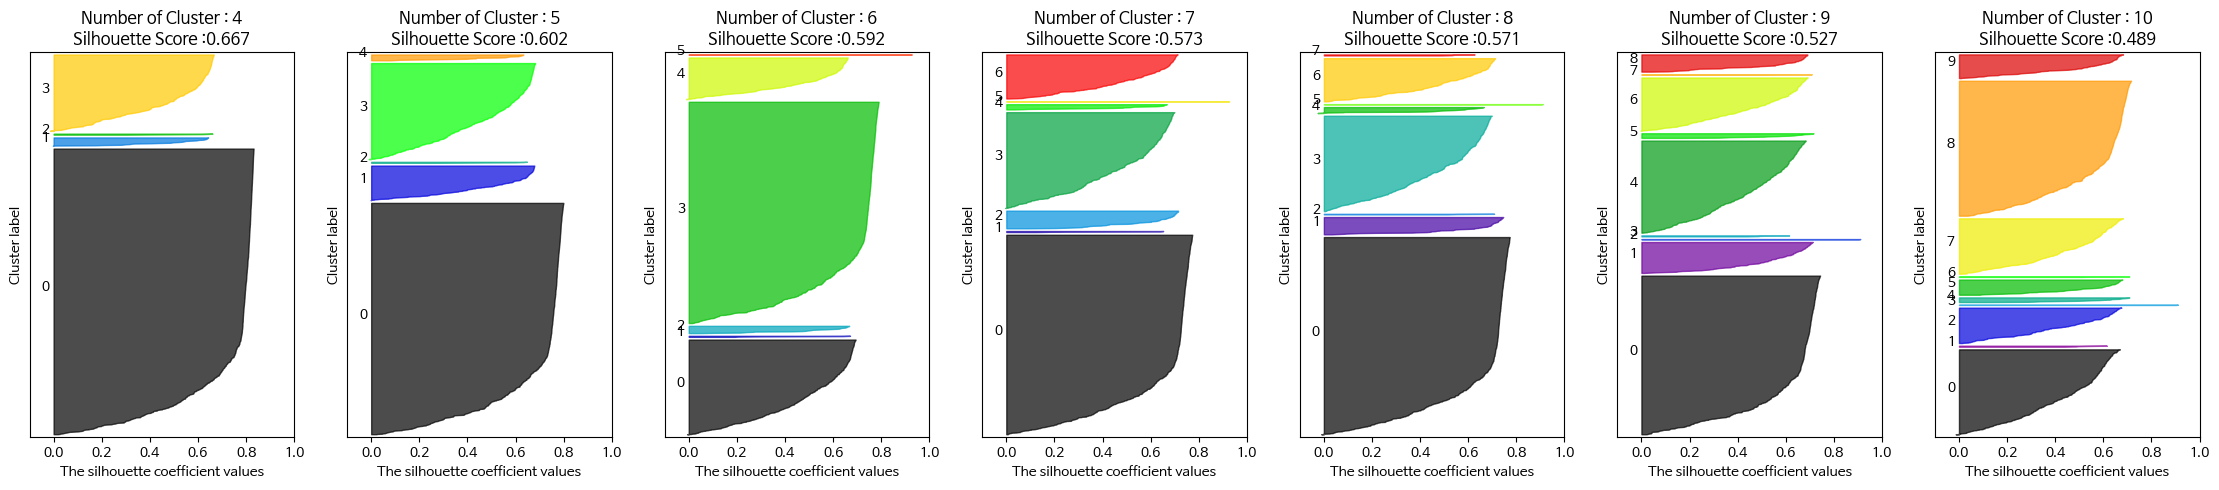

In [10]:
### 여러개의 클러스터링 갯수를 List로 입력 받아 각각의 실루엣 계수를 면적으로 시각화한 함수 작성
def visualize_silhouette(cluster_lists, X_features):

    from sklearn.datasets import make_blobs
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_samples, silhouette_score

    import matplotlib.pyplot as plt
    import matplotlib.cm as cm
    import math

    # 입력값으로 클러스터링 갯수들을 리스트로 받아서, 각 갯수별로 클러스터링을 적용하고 실루엣 개수를 구함
    n_cols = len(cluster_lists)

    # plt.subplots()으로 리스트에 기재된 클러스터링 수만큼의 sub figures를 가지는 axs 생성
    fig, axs = plt.subplots(figsize=(4*n_cols, 5), nrows=1, ncols=n_cols)

    # cluster label 추출
    labels = {}

    # 리스트에 기재된 클러스터링 갯수들을 차례로 iteration 수행하면서 실루엣 개수 시각화
    for ind, n_cluster in enumerate(cluster_lists):

        # KMeans 클러스터링 수행하고, 실루엣 스코어와 개별 데이터의 실루엣 값 계산.
        clusterer = KMeans(n_clusters = n_cluster, max_iter=500, random_state=13)
        cluster_labels = clusterer.fit_predict(X_features)
        labels[n_cluster] = cluster_labels
        centers = clusterer.cluster_centers_

        sil_avg = silhouette_score(X_features, cluster_labels)
        sil_values = silhouette_samples(X_features, cluster_labels)

        y_lower = 10
        axs[ind].set_title('Number of Cluster : '+ str(n_cluster)+'\n' \
                          'Silhouette Score :' + str(round(sil_avg,3)) )
        axs[ind].set_xlabel("The silhouette coefficient values")
        axs[ind].set_ylabel("Cluster label")
        axs[ind].set_xlim([-0.1, 1])
        axs[ind].set_ylim([0, len(X_features) + (n_cluster + 1) * 10])
        axs[ind].set_yticks([])  # Clear the yaxis labels / ticks
        axs[ind].set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])

        # 클러스터링 갯수별로 fill_betweenx( )형태의 막대 그래프 표현.
        for i in range(n_cluster):
            ith_cluster_sil_values = sil_values[cluster_labels==i]
            ith_cluster_sil_values.sort()

            size_cluster_i = ith_cluster_sil_values.shape[0]
            y_upper = y_lower + size_cluster_i

            color = cm.nipy_spectral(float(i) / n_cluster)
            axs[ind].fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil_values, \
                                facecolor=color, edgecolor=color, alpha=0.7)
            axs[ind].text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
            y_lower = y_upper + 10

    return labels

# cluster 개수를 2개, 3개, 4개, 5개, 6개, 7개 일때의 클러스터별 실루엣 계수 평균값을 시각화
visualize_silhouette([4, 5, 6, 7, 8, 9, 10], kmeans_df.drop('고객ID', axis=1))

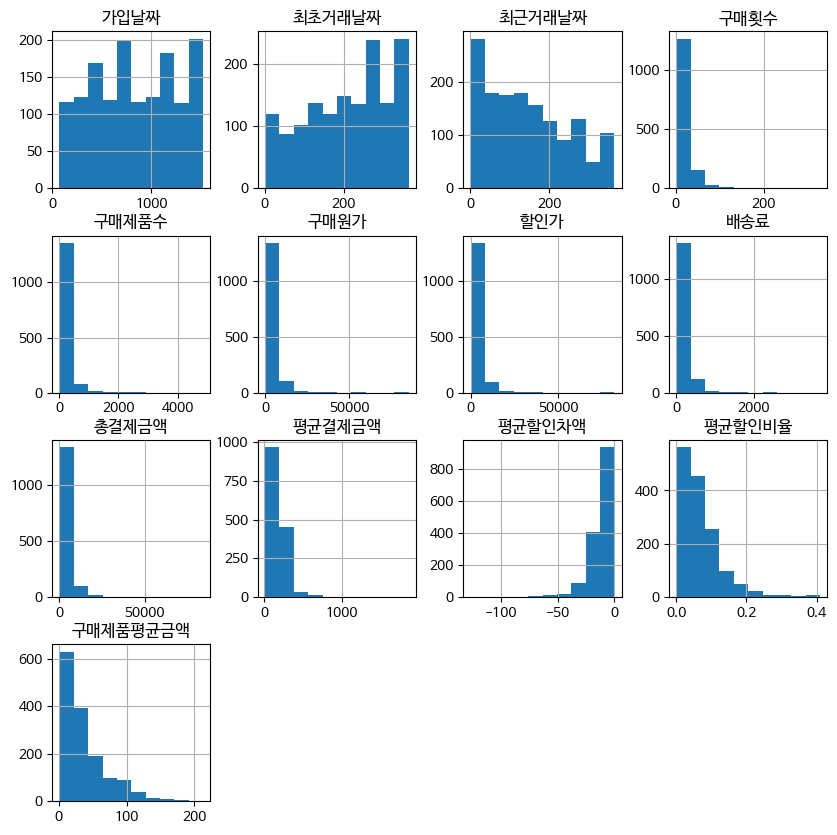

In [11]:
customer_buyinginfo_df.hist(figsize = (10, 10));

---
# Features 수 줄이기 -> 8 Features

In [12]:
new_df = customer_buyinginfo_df.copy()
new_features_df = new_df.drop(['가입날짜', '고객ID', '평균결제금액', '평균할인차액', '평균할인비율', '구매제품평균금액'], axis=1)
new_features_df.head()

,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액
0,108,108,1,3,35.69,24.98,75.00,99.98
1,283,60,31,342,15902.78,15021.67,286.46,15308.13
2,193,74,8,209,1645.73,1492.42,81.07,1573.49
3,18,18,11,21,1508.36,1339.57,82.39,1421.96
4,108,108,13,56,1594.23,1369.93,154.49,1524.42


{4: array([0, 1, 0, ..., 0, 0, 2], dtype=int32),
 5: array([0, 1, 0, ..., 0, 0, 3], dtype=int32),
 6: array([2, 3, 2, ..., 2, 2, 0], dtype=int32),
 7: array([0, 2, 0, ..., 0, 0, 4], dtype=int32),
 8: array([3, 2, 3, ..., 3, 3, 7], dtype=int32),
 9: array([0, 1, 5, ..., 0, 0, 8], dtype=int32),
 10: array([8, 1, 0, ..., 8, 8, 9], dtype=int32)}

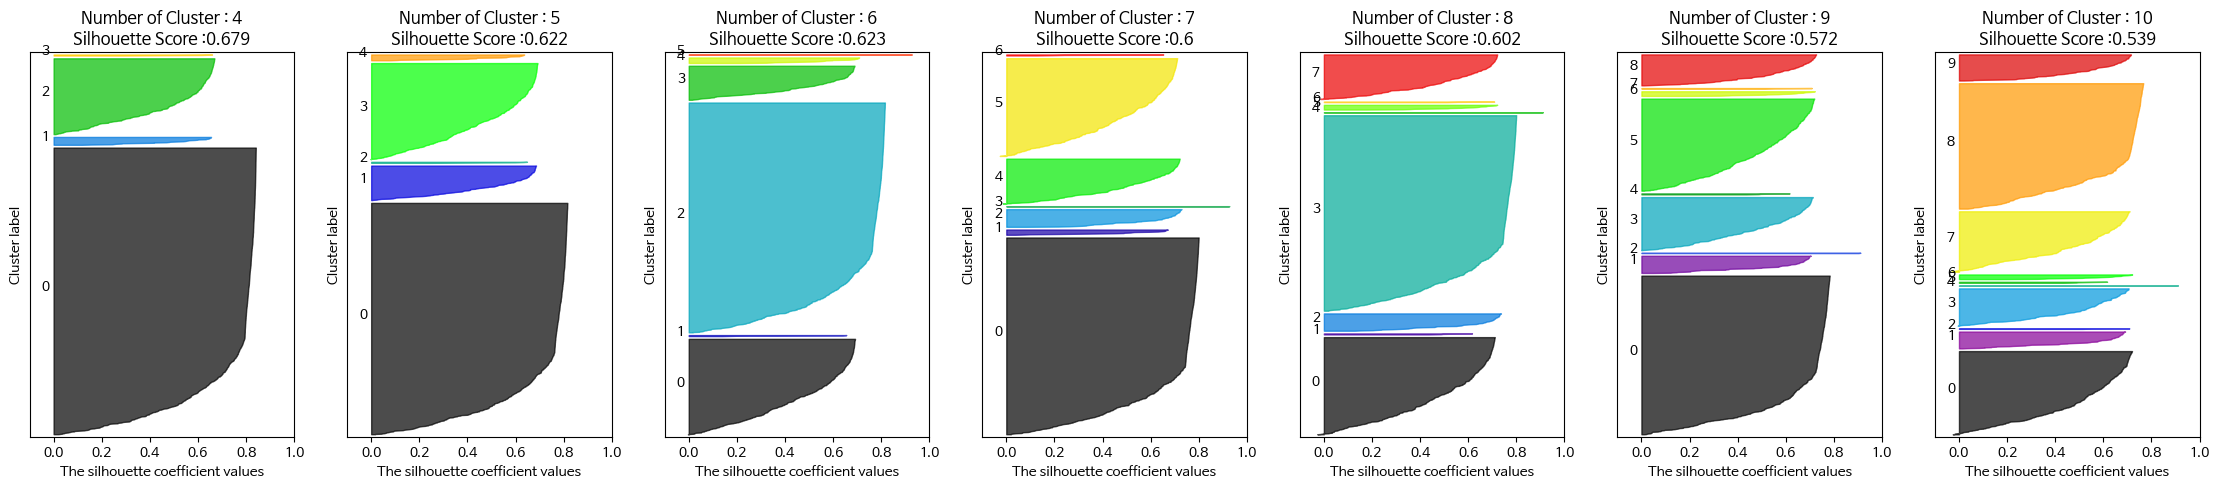

In [13]:
# cluster 개수를 2개, 3개, 4개, 5개, 6개, 7개 일때의 클러스터별 실루엣 계수 평균값을 시각화
visualize_silhouette([4, 5, 6, 7, 8, 9, 10], new_features_df)

---
# 8 Features 데이터 분포 변환하기
### Robust Scaler 적용하기
- 평균과 분산 대신에 중간값과 사분위값 사용
중앙값(median)과 IQR(interquartile range) 사용. 아웃라이어의 영향을 최소화
- RobustScaler는 특성들이 같은 스케일을 갖게 되지만 평균대신 중앙값을 사용 ==> 극단값에 영향을 받지 않음
- https://wikidocs.net/89704
- https://m.blog.naver.com/PostView.naver?isHttpsRedirect=true&blogId=demian7607&logNo=222009975984

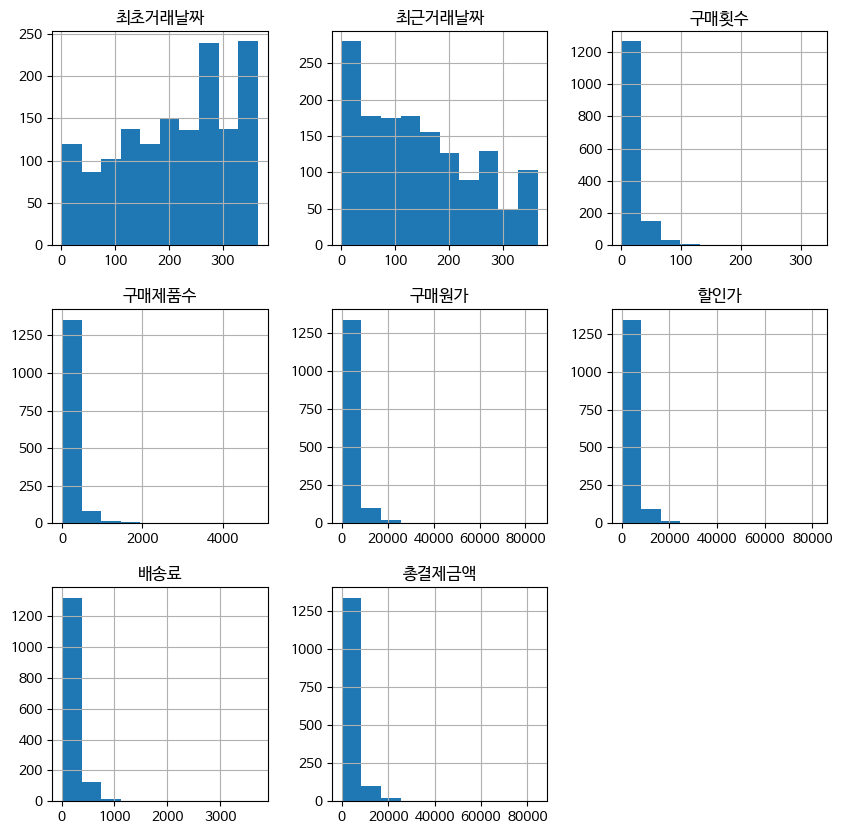

In [14]:
new_features_df.hist(figsize=(10, 10));

In [15]:
rs_features_df = new_features_df.copy()

In [16]:
from sklearn.preprocessing import RobustScaler
rs = RobustScaler()

rs_features_df = pd.DataFrame(rs.fit_transform(rs_features_df), columns = rs_features_df.columns)
rs_features_df.head()


,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액
0,-0.691729,-0.145455,-0.555556,-0.364780,-0.520975,-0.520220,-0.111722,-0.505632
1,0.360902,-0.436364,1.111111,1.767296,3.841310,3.883231,1.180663,3.768004
2,-0.180451,-0.351515,-0.166667,0.930818,-0.078332,-0.089338,-0.074624,-0.091561
3,-1.233083,-0.690909,0.000000,-0.251572,-0.116099,-0.134219,-0.066557,-0.134143
4,-0.691729,-0.145455,0.111111,-0.031447,-0.092491,-0.125304,0.374099,-0.105350


In [17]:
rs_features_df.describe()

,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액
count,1468.000000,1468.000000,1468.000000,1468.000000,1.468000e+03,1.468000e+03,1468.000000,1468.000000
mean,-0.080293,0.080559,0.396723,0.636150,4.403231e-01,4.406858e-01,0.424875,0.438651
std,0.629640,0.617800,1.387579,1.964617,1.550980e+00,1.556256e+00,1.453519,1.551158
min,-1.335338,-0.793939,-0.555556,-0.377358,-5.304845e-01,-5.272637e-01,-0.533431,-0.531763
25%,-0.565414,-0.460606,-0.333333,-0.264151,-3.301036e-01,-3.298553e-01,-0.334922,-0.332876
50%,0.000000,0.000000,0.000000,0.000000,-3.125213e-17,-3.339343e-17,0.000000,0.000000
75%,0.434586,0.539394,0.666667,0.735849,6.698964e-01,6.701447e-01,0.665078,0.667124
max,0.854135,1.412121,17.611111,30.238994,2.292354e+01,2.357167e+01,22.136903,23.185120


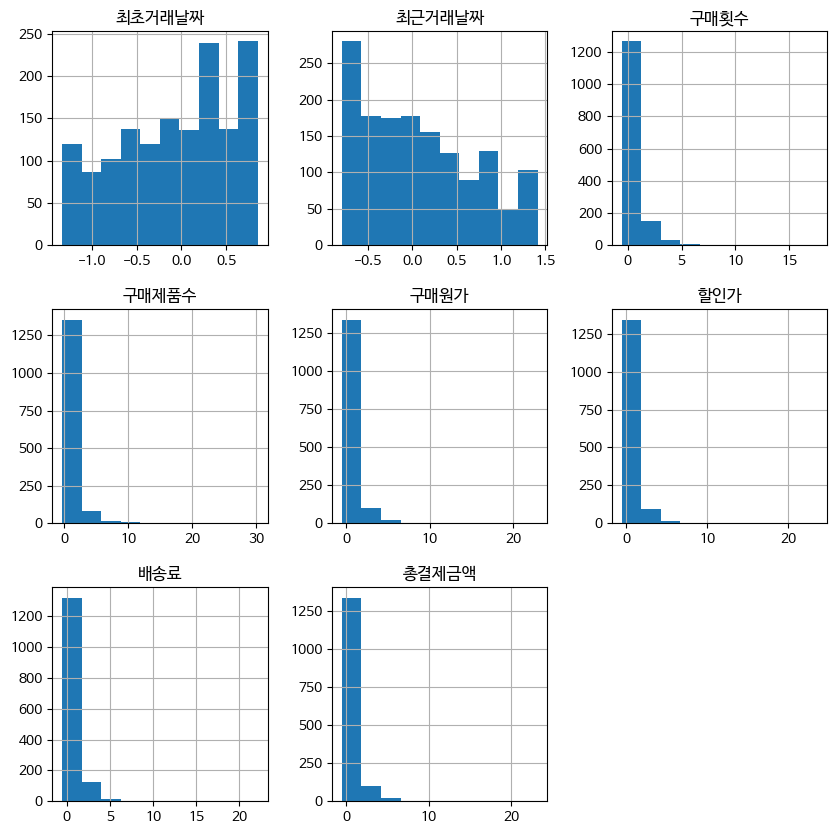

In [18]:
rs_features_df.hist(figsize=(10, 10));

{4: array([0, 3, 0, ..., 0, 0, 3], dtype=int32),
 5: array([0, 3, 0, ..., 0, 0, 1], dtype=int32),
 6: array([5, 3, 5, ..., 0, 5, 2], dtype=int32),
 7: array([0, 3, 4, ..., 0, 0, 6], dtype=int32),
 8: array([0, 2, 0, ..., 7, 0, 4], dtype=int32),
 9: array([8, 0, 8, ..., 1, 8, 5], dtype=int32),
 10: array([6, 5, 6, ..., 2, 6, 5], dtype=int32)}

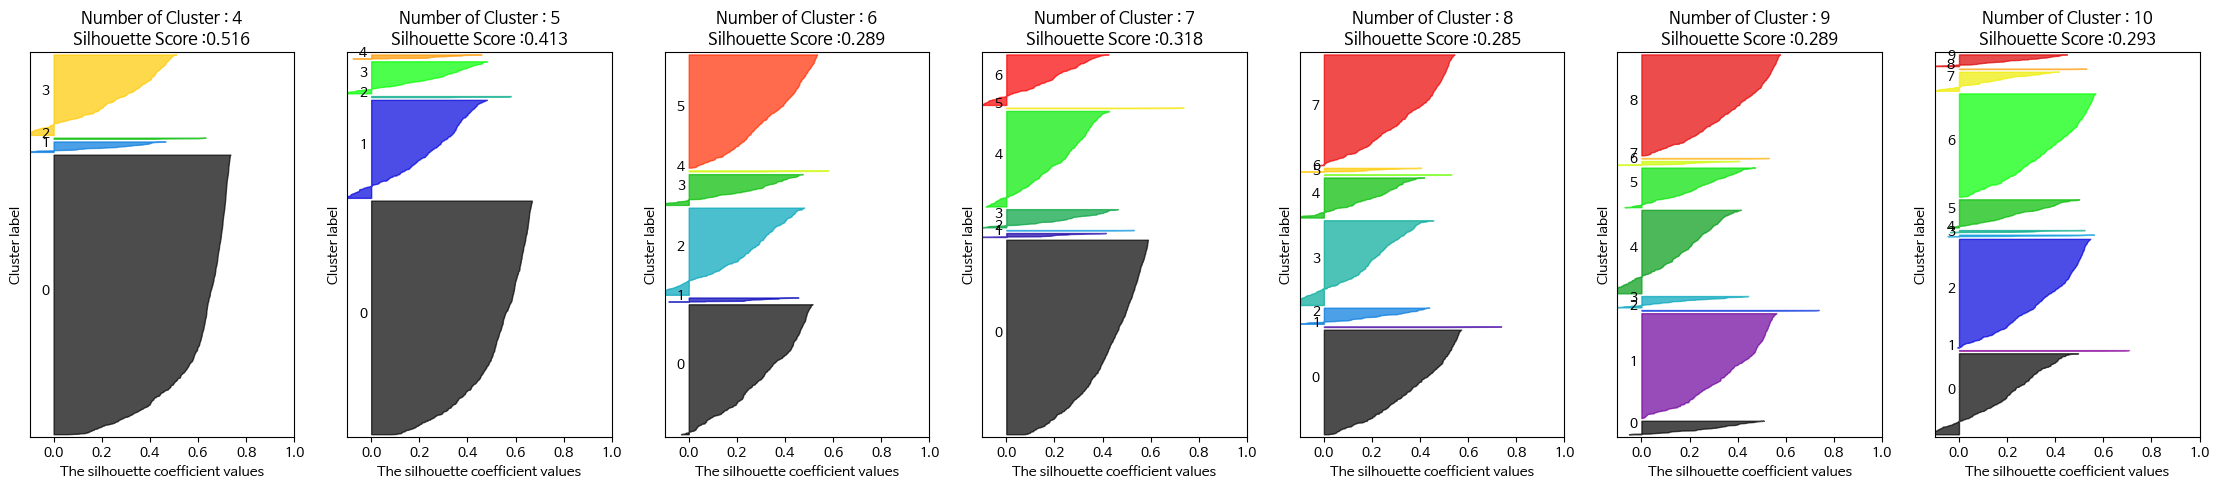

In [19]:
# cluster 개수를 2개, 3개, 4개, 5개, 6개, 7개 일때의 클러스터별 실루엣 계수 평균값을 시각화
visualize_silhouette([4, 5, 6, 7, 8, 9, 10], rs_features_df)

---
## MinMax Scaler

In [20]:
mm_features_df = new_features_df.copy()

In [21]:
from sklearn.preprocessing import MinMaxScaler
mm = MinMaxScaler()

mm_features_df = pd.DataFrame(mm.fit_transform(mm_features_df), columns = mm_features_df.columns)
mm_features_df.head()

,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액
0,0.293956,0.293956,0.000000,0.000411,0.000405,0.000292,0.018602,0.001102
1,0.774725,0.162088,0.091743,0.070049,0.186398,0.183016,0.075610,0.181296
2,0.527473,0.200549,0.021407,0.042728,0.019278,0.018172,0.020238,0.018561
3,0.046703,0.046703,0.030581,0.004108,0.017668,0.016310,0.020594,0.016765
4,0.293956,0.293956,0.036697,0.011298,0.018675,0.016680,0.040032,0.017979


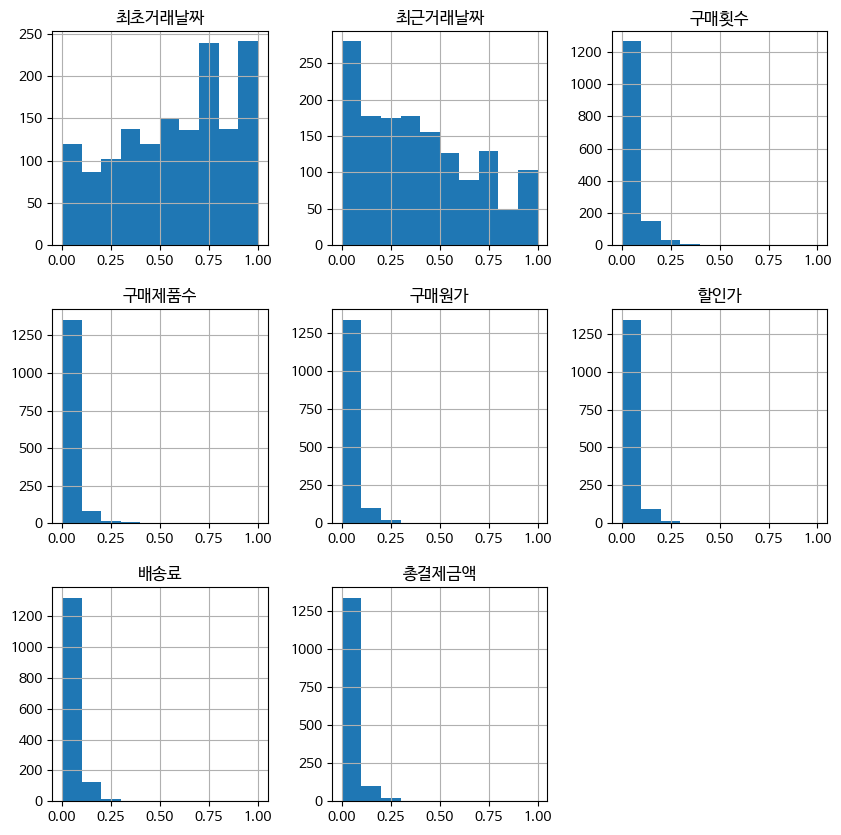

In [22]:
mm_features_df.hist(figsize=(10, 10));

{4: array([0, 1, 2, ..., 2, 0, 0], dtype=int32),
 5: array([0, 2, 3, ..., 3, 0, 0], dtype=int32),
 6: array([1, 0, 1, ..., 4, 3, 1], dtype=int32),
 7: array([6, 1, 6, ..., 2, 0, 6], dtype=int32),
 8: array([1, 2, 5, ..., 7, 3, 5], dtype=int32),
 9: array([5, 3, 6, ..., 7, 0, 6], dtype=int32),
 10: array([0, 8, 2, ..., 6, 4, 2], dtype=int32)}

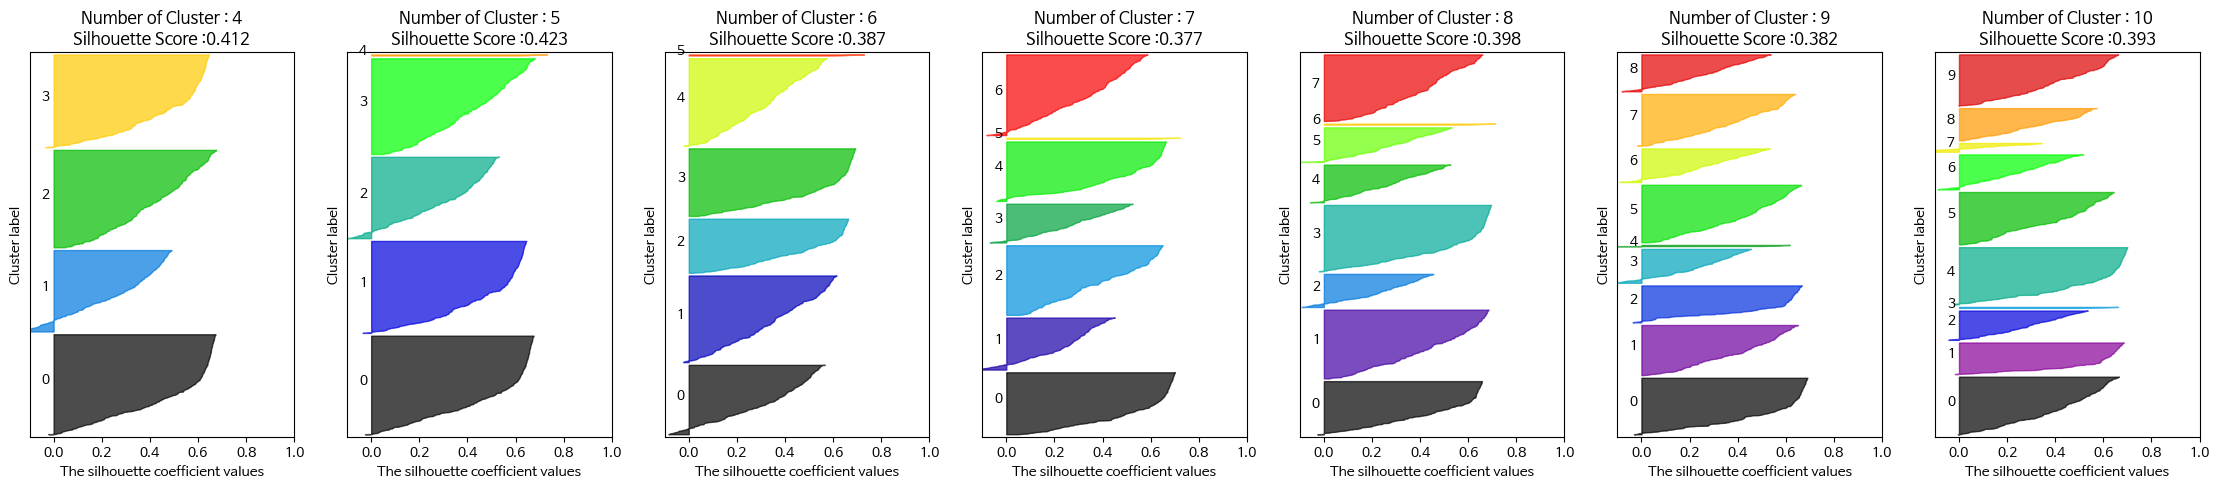

In [23]:
visualize_silhouette([4, 5, 6, 7, 8, 9, 10], mm_features_df)

---
## Standard Scaler

In [24]:
ss_features_df = new_features_df.copy()

In [25]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()

ss_features_df = pd.DataFrame(ss.fit_transform(ss_features_df), columns = ss_features_df.columns)
ss_features_df.head()

,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액
0,-0.971419,-0.365961,-0.686522,-0.509652,-0.620011,-0.617657,-0.369297,-0.608968
1,0.700949,-0.837001,0.515021,0.575955,2.193545,2.212822,0.520148,2.147098
2,-0.159126,-0.699614,-0.406162,0.150039,-0.334519,-0.340692,-0.343765,-0.341934
3,-1.831494,-1.249160,-0.286007,-0.452009,-0.358877,-0.369541,-0.338213,-0.369394
4,-0.971419,-0.365961,-0.205905,-0.339926,-0.343651,-0.363811,-0.034946,-0.350826


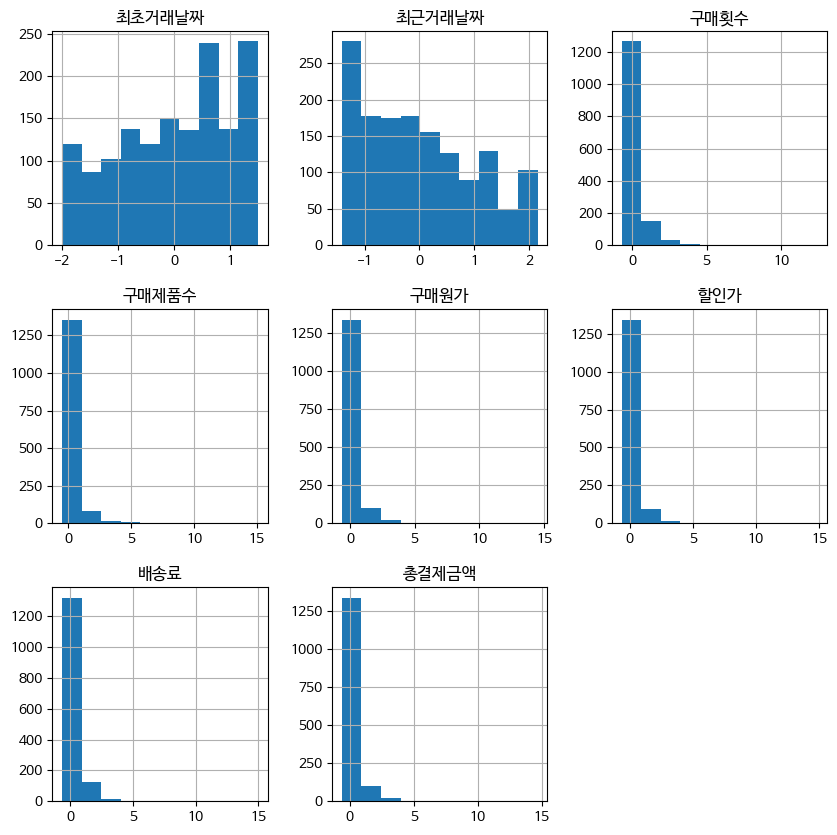

In [26]:
ss_features_df.hist(figsize=(10, 10));

{4: array([3, 2, 3, ..., 0, 3, 2], dtype=int32),
 5: array([0, 4, 0, ..., 2, 0, 4], dtype=int32),
 6: array([5, 3, 5, ..., 2, 5, 3], dtype=int32),
 7: array([3, 4, 3, ..., 3, 0, 4], dtype=int32),
 8: array([5, 4, 5, ..., 5, 0, 4], dtype=int32),
 9: array([4, 3, 6, ..., 6, 4, 0], dtype=int32),
 10: array([7, 8, 0, ..., 0, 7, 3], dtype=int32)}

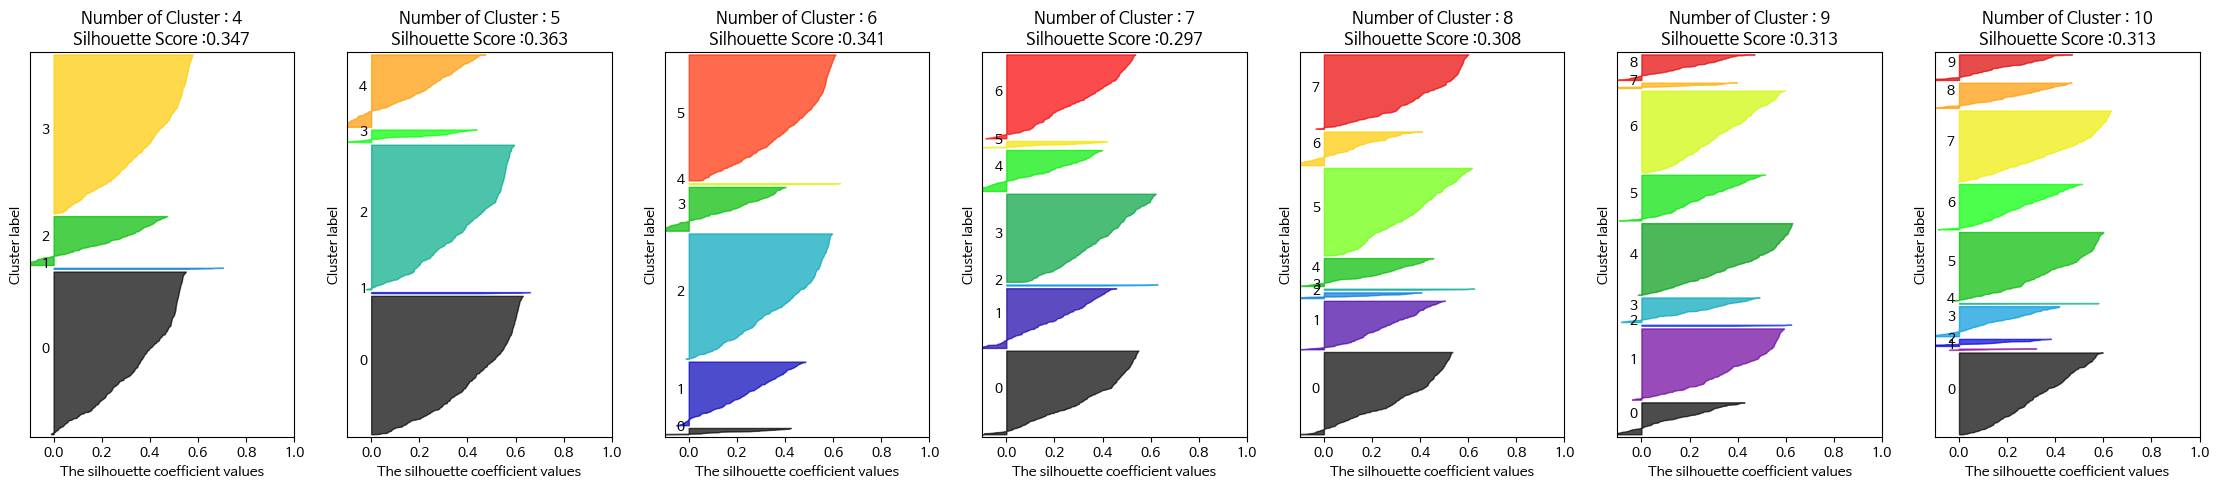

In [27]:
visualize_silhouette([4, 5, 6, 7, 8, 9, 10], ss_features_df)

---
## Log Scale

In [28]:
log_features_df = new_features_df.copy()

In [29]:
log_features_df = np.log(log_features_df)
log_features_df.head()

,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액
0,4.682131,4.682131,0.000000,1.098612,3.574871,3.218076,4.317488,4.604970
1,5.645447,4.094345,3.433987,5.834811,9.674249,9.617249,5.657599,9.636139
2,5.262690,4.304065,2.079442,5.342334,7.405939,7.308154,4.395313,7.361051
3,2.890372,2.890372,2.397895,3.044522,7.318778,7.200104,4.411464,7.259791
4,4.682131,4.682131,2.564949,4.025352,7.374146,7.222515,5.040129,7.329369


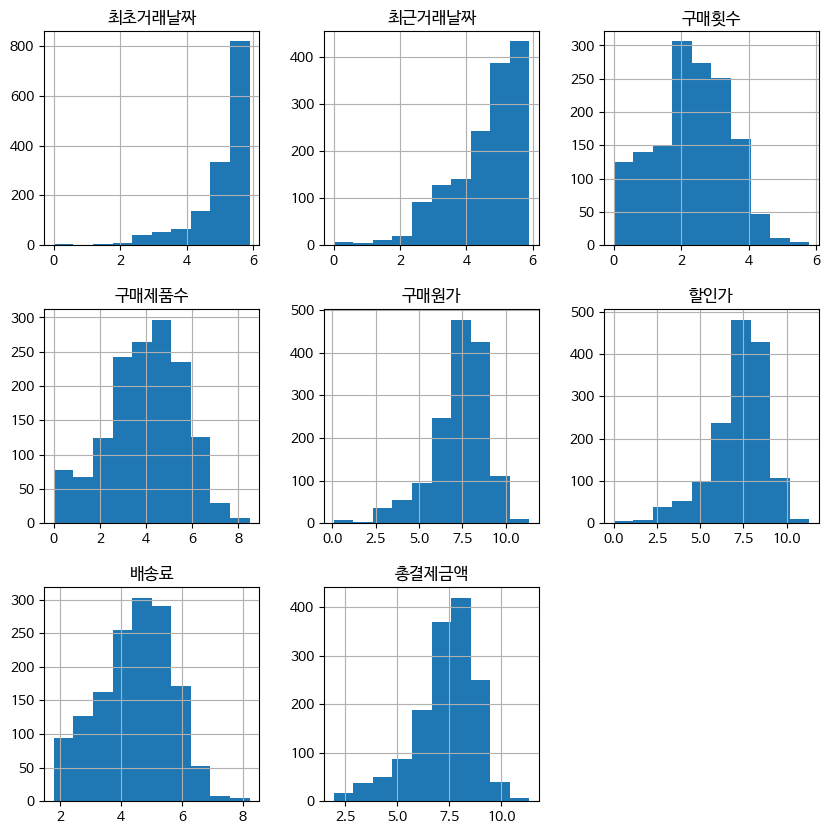

In [30]:
log_features_df.hist(figsize=(10, 10));

{4: array([1, 3, 0, ..., 1, 1, 3], dtype=int32),
 5: array([0, 1, 4, ..., 0, 0, 1], dtype=int32),
 6: array([3, 2, 4, ..., 5, 5, 2], dtype=int32),
 7: array([0, 1, 3, ..., 6, 6, 4], dtype=int32),
 8: array([5, 2, 1, ..., 3, 3, 4], dtype=int32),
 9: array([3, 7, 0, ..., 2, 2, 7], dtype=int32),
 10: array([3, 5, 0, ..., 2, 2, 7], dtype=int32)}

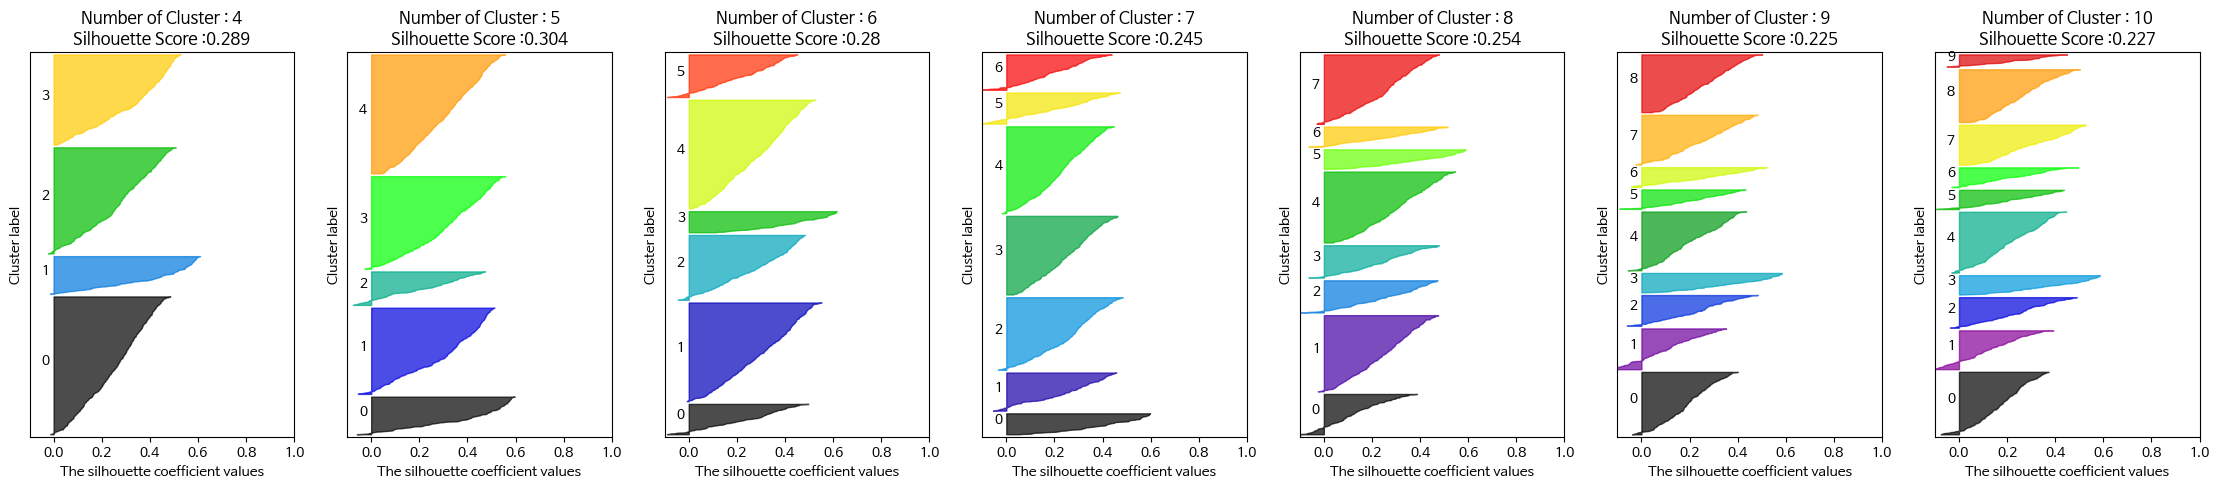

In [31]:
visualize_silhouette([4, 5, 6, 7, 8, 9, 10], log_features_df)

---
# IQR 이상치 제외 + Kmeans -> df
- https://hwi-doc.tistory.com/entry/IQR-%EB%B0%A9%EC%8B%9D%EC%9D%84-%EC%9D%B4%EC%9A%A9%ED%95%9C-%EC%9D%B4%EC%83%81%EC%B9%98-%EB%8D%B0%EC%9D%B4%ED%84%B0Outlier-%EC%A0%9C%EA%B1%B0
- 총결제금액 기준으로 이상치 선정
- 제외한 이상치를 하위 그룹, 상위 그룹 2개로 별도 구분

In [32]:
def get_outlier(df=None, column=None, weight=1.5):
  # target 값과 상관관계가 높은 열을 우선적으로 진행
  quantile_25 = np.percentile(df[column].values, 25)
  quantile_75 = np.percentile(df[column].values, 75)

  IQR = quantile_75 - quantile_25
  IQR_weight = IQR*weight

  lowest = quantile_25 - IQR_weight
  highest = quantile_75 + IQR_weight

  outlier_idx = df[column][ (df[column] < lowest) | (df[column] > highest) ].index
  return outlier_idx, lowest, highest

# 함수 사용해서 이상치 값 삭제
outlier_idx, low, high = get_outlier(df=new_features_df, column='총결제금액', weight=1.5)
new_features_drop_iqr = new_features_df.drop(outlier_idx, axis=0)

In [33]:
low, high

(-4623.14625, 9611.24375)

- 총결제금액에서 -4623.14625 값은 존재하지 않으므로 하위 그룹은 없다고 보아야 함

In [34]:
new_features_drop_iqr.describe()

,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액
count,1368.000000,1368.000000,1368.000000,1368.000000,1368.000000,1368.000000,1368.000000,1368.000000
mean,206.151316,150.369883,13.703947,112.125731,2490.940263,2320.874693,122.307142,2443.181835
std,104.531762,101.717989,12.049250,155.027016,2342.555282,2184.788053,117.051875,2284.447601
min,1.000000,1.000000,1.000000,1.000000,1.100000,0.990000,6.000000,6.990000
25%,127.000000,62.000000,5.000000,17.000000,665.585000,615.725000,36.000000,659.567500
50%,215.500000,137.000000,10.000000,53.000000,1763.100000,1615.780000,86.365000,1718.385000
75%,290.000000,223.000000,20.000000,144.000000,3680.255000,3402.367500,172.715000,3599.787500
max,365.000000,365.000000,69.000000,1202.000000,10875.750000,9363.590000,868.650000,9551.460000


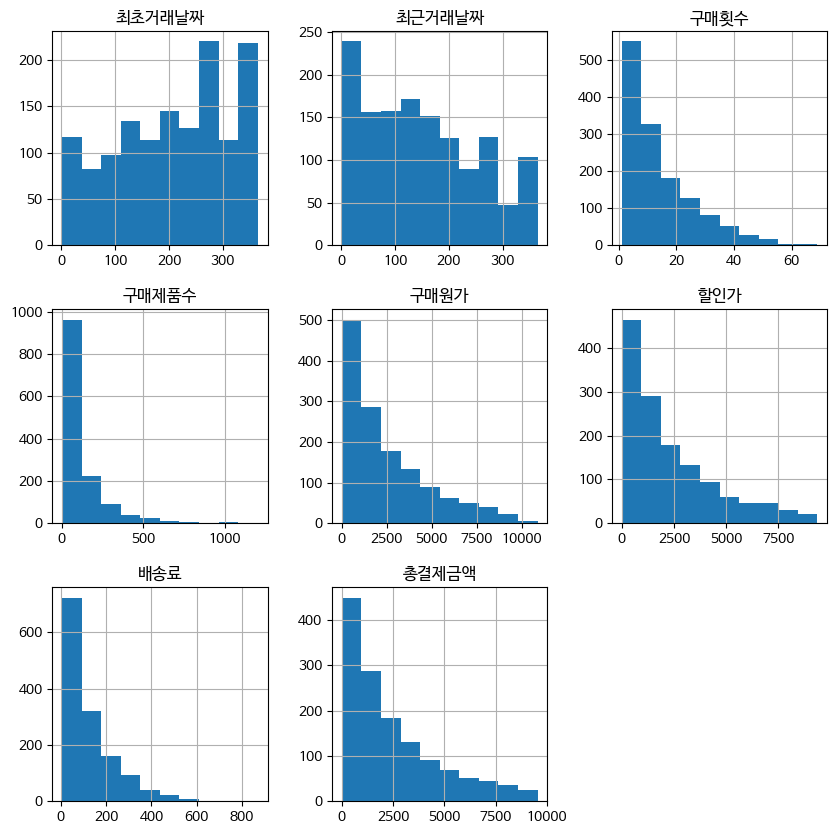

In [35]:
new_features_drop_iqr.hist(figsize=(10, 10));

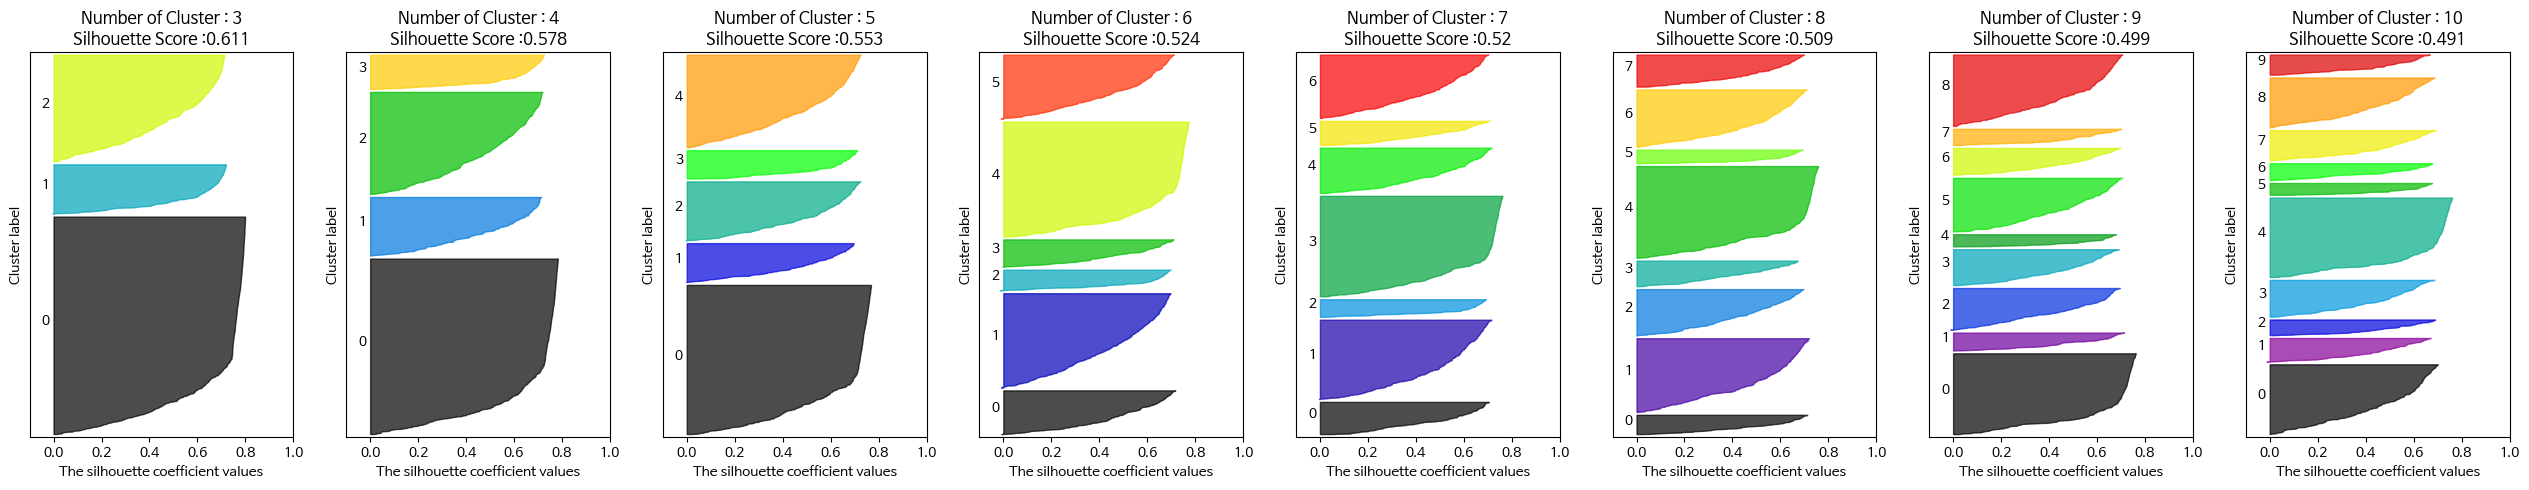

In [36]:
new_features_drop_iqr_labels = visualize_silhouette([3, 4, 5, 6, 7, 8, 9, 10], new_features_drop_iqr)

In [37]:
new_features_drop_iqr_labels[4]

array([0, 2, 0, ..., 0, 0, 3], dtype=int32)

## Cluster 0 한 번 더 쪼개기
- 현재 이상치 1개 + 4개 Clustered Group



In [38]:
new_features_drop_iqr_cluster = new_features_drop_iqr.copy()
new_features_drop_iqr_cluster['Cluster'] = new_features_drop_iqr_labels[4]
new_features_drop_iqr_cluster

,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,Cluster
0,108,108,1,3,35.69,24.98,75.00,99.98,0
2,193,74,8,209,1645.73,1492.42,81.07,1573.49,2
3,18,18,11,21,1508.36,1339.57,82.39,1421.96,0
4,108,108,13,56,1594.23,1369.93,154.49,1524.42,0
5,131,131,3,86,696.47,688.02,18.00,706.02,0
...,...,...,...,...,...,...,...,...,...
1463,271,271,3,46,595.58,582.38,94.35,676.73,0
1464,193,88,19,141,2640.23,2384.13,222.05,2606.18,2
1465,271,195,2,10,119.58,115.40,12.50,127.90,0
1466,70,70,1,2,327.80,327.80,6.00,333.80,0


In [39]:
new_features_drop_iqr_cluster_0 = new_features_drop_iqr_cluster[new_features_drop_iqr_cluster['Cluster'] == 0]
new_features_drop_iqr_cluster_0

,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,Cluster
0,108,108,1,3,35.69,24.98,75.00,99.98,0
3,18,18,11,21,1508.36,1339.57,82.39,1421.96,0
4,108,108,13,56,1594.23,1369.93,154.49,1524.42,0
5,131,131,3,86,696.47,688.02,18.00,706.02,0
7,25,25,5,22,526.96,492.60,38.48,531.08,0
...,...,...,...,...,...,...,...,...,...
1458,109,109,1,50,109.45,76.61,6.00,82.61,0
1462,180,180,2,4,58.35,58.35,12.50,70.85,0
1463,271,271,3,46,595.58,582.38,94.35,676.73,0
1465,271,195,2,10,119.58,115.40,12.50,127.90,0


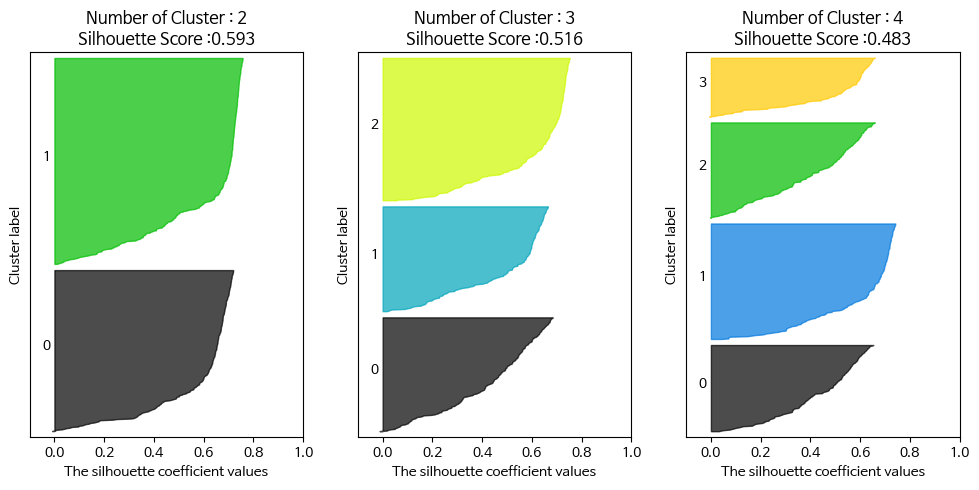

In [40]:
new_features_drop_iqr_cluster_0_labels = visualize_silhouette([2, 3, 4], new_features_drop_iqr_cluster_0)

In [41]:
new_features_drop_iqr_cluster_0['Cluster'] = new_features_drop_iqr_cluster_0_labels[2]
new_features_drop_iqr_cluster_0['Cluster'].replace({0:4, 1:5}, inplace=True)
new_features_drop_iqr_cluster_0

<ipython-input-41-23fe19f8e061>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_features_drop_iqr_cluster_0['Cluster'] = new_features_drop_iqr_cluster_0_labels[2]
<ipython-input-41-23fe19f8e061>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_features_drop_iqr_cluster_0['Cluster'].replace({0:4, 1:5}, inplace=True)


,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,Cluster
0,108,108,1,3,35.69,24.98,75.00,99.98,5
3,18,18,11,21,1508.36,1339.57,82.39,1421.96,4
4,108,108,13,56,1594.23,1369.93,154.49,1524.42,4
5,131,131,3,86,696.47,688.02,18.00,706.02,4
7,25,25,5,22,526.96,492.60,38.48,531.08,5
...,...,...,...,...,...,...,...,...,...
1458,109,109,1,50,109.45,76.61,6.00,82.61,5
1462,180,180,2,4,58.35,58.35,12.50,70.85,5
1463,271,271,3,46,595.58,582.38,94.35,676.73,5
1465,271,195,2,10,119.58,115.40,12.50,127.90,5


In [42]:
for idx in new_features_drop_iqr_cluster_0.index:
  new_features_drop_iqr_cluster.loc[idx, 'Cluster'] = new_features_drop_iqr_cluster_0.loc[idx, 'Cluster']

new_features_drop_iqr_cluster

,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,Cluster
0,108,108,1,3,35.69,24.98,75.00,99.98,5
2,193,74,8,209,1645.73,1492.42,81.07,1573.49,2
3,18,18,11,21,1508.36,1339.57,82.39,1421.96,4
4,108,108,13,56,1594.23,1369.93,154.49,1524.42,4
5,131,131,3,86,696.47,688.02,18.00,706.02,4
...,...,...,...,...,...,...,...,...,...
1463,271,271,3,46,595.58,582.38,94.35,676.73,5
1464,193,88,19,141,2640.23,2384.13,222.05,2606.18,2
1465,271,195,2,10,119.58,115.40,12.50,127.90,5
1466,70,70,1,2,327.80,327.80,6.00,333.80,5


## 이상치 그룹을 6으로 추가하기
- 이상치 1개 + clustered group 6개


In [43]:
new_features_df_high = new_features_df[new_features_df['총결제금액'] >= high]
new_features_df_high['Cluster'] = [6] * len(new_features_df_high)
new_features_df_high

<ipython-input-43-7da481146b72>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_features_df_high['Cluster'] = [6] * len(new_features_df_high)


,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,Cluster
1,283,60,31,342,15902.78,15021.67,286.46,15308.13,6
8,180,41,37,421,10842.99,10473.22,334.50,10807.72,6
26,357,266,55,1494,15444.70,15042.48,1290.23,16332.71,6
30,104,104,57,799,10854.35,9775.49,526.07,10301.56,6
33,348,16,70,279,15345.18,14486.54,567.16,15053.70,6
...,...,...,...,...,...,...,...,...,...
1397,278,20,35,1397,13640.28,13170.16,320.93,13491.09,6
1411,347,19,95,716,15743.19,14979.30,1004.99,15984.29,6
1432,249,169,77,374,11892.47,11383.12,514.16,11897.28,6
1433,320,107,120,1230,21261.91,19923.70,1214.95,21138.65,6


In [44]:
iqr_df = pd.concat([new_features_drop_iqr_cluster, new_features_df_high], axis=0).sort_index()
iqr_df

,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,Cluster
0,108,108,1,3,35.69,24.98,75.00,99.98,5
1,283,60,31,342,15902.78,15021.67,286.46,15308.13,6
2,193,74,8,209,1645.73,1492.42,81.07,1573.49,2
3,18,18,11,21,1508.36,1339.57,82.39,1421.96,4
4,108,108,13,56,1594.23,1369.93,154.49,1524.42,4
...,...,...,...,...,...,...,...,...,...
1463,271,271,3,46,595.58,582.38,94.35,676.73,5
1464,193,88,19,141,2640.23,2384.13,222.05,2606.18,2
1465,271,195,2,10,119.58,115.40,12.50,127.90,5
1466,70,70,1,2,327.80,327.80,6.00,333.80,5


- 총 6개 그룹으로 구분

In [45]:
iqr_df = pd.concat([customer_buyinginfo_df, iqr_df['Cluster']], axis=1)
iqr_df

,고객ID,가입날짜,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,평균결제금액,평균할인차액,평균할인비율,구매제품평균금액,Cluster
0,USER_0000,988,108,108,1,3,35.69,24.98,75.00,99.98,99.98,-10.71,0.11,8.33,5
1,USER_0001,659,283,60,31,342,15902.78,15021.67,286.46,15308.13,493.81,-28.42,0.06,43.92,6
2,USER_0002,1205,193,74,8,209,1645.73,1492.42,81.07,1573.49,196.69,-19.16,0.10,7.14,2
3,USER_0003,764,18,18,11,21,1508.36,1339.57,82.39,1421.96,129.27,-15.34,0.12,63.79,4
4,USER_0004,988,108,108,13,56,1594.23,1369.93,154.49,1524.42,117.26,-17.25,0.15,24.46,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1463,USER_1463,183,271,271,3,46,595.58,582.38,94.35,676.73,225.58,-4.40,0.02,12.66,5
1464,USER_1464,1352,193,88,19,141,2640.23,2384.13,222.05,2606.18,137.17,-13.48,0.10,16.91,2
1465,USER_1465,764,271,195,2,10,119.58,115.40,12.50,127.90,63.95,-2.09,0.03,11.54,5
1466,USER_1466,1499,70,70,1,2,327.80,327.80,6.00,333.80,333.80,0.00,0.00,163.90,5


---
# 8개 Features PCA + Kmeans
- 2차원으로 축소

In [46]:
from sklearn.decomposition import PCA

# PCA 변환
pca = PCA(n_components=2)
principalComponents = pca.fit_transform(new_features_df)
pca_df = pd.DataFrame(data=principalComponents, columns=['1st', '2nd'])
pca_df

,1st,2nd
0,-5852.953742,9.100289
1,20749.573291,385.916257
2,-3219.465087,-44.187432
3,-3479.577942,153.578519
4,-3349.645598,71.818550
...,...,...
1463,-4874.143900,-115.562288
1464,-1532.503263,3.583816
1465,-5737.754685,-46.268029
1466,-5376.986760,63.813297


In [47]:
### 여러개의 클러스터링 갯수를 List로 입력 받아 각각의 실루엣 계수를 면적으로 시각화한 함수 작성
def visualize_silhouette_2d(cluster_lists, X_features):

    from sklearn.datasets import make_blobs
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_samples, silhouette_score

    import matplotlib.pyplot as plt
    import matplotlib.cm as cm
    import math

    # 입력값으로 클러스터링 갯수들을 리스트로 받아서, 각 갯수별로 클러스터링을 적용하고 실루엣 개수를 구함
    n_cols = len(cluster_lists)

    # plt.subplots()으로 리스트에 기재된 클러스터링 수만큼의 sub figures를 가지는 axs 생성
    fig, axs = plt.subplots(figsize=(4*n_cols, 8), nrows=2, ncols=n_cols)

    # cluster label 추출
    labels = {}

    # 리스트에 기재된 클러스터링 갯수들을 차례로 iteration 수행하면서 실루엣 개수 시각화
    for ind, n_cluster in enumerate(cluster_lists):

        # KMeans 클러스터링 수행하고, 실루엣 스코어와 개별 데이터의 실루엣 값 계산.
        clusterer = KMeans(n_clusters = n_cluster, max_iter=500, random_state=13)
        cluster_labels = clusterer.fit_predict(X_features)
        labels[n_cluster] = cluster_labels
        centers = clusterer.cluster_centers_

        sil_avg = silhouette_score(X_features, cluster_labels)
        sil_values = silhouette_samples(X_features, cluster_labels)

        y_lower = 10
        axs[0, ind].set_title('Number of Cluster : '+ str(n_cluster)+'\n' \
                          'Silhouette Score :' + str(round(sil_avg,3)) )
        axs[0, ind].set_xlabel("The silhouette coefficient values")
        axs[0, ind].set_ylabel("Cluster label")
        axs[0, ind].set_xlim([-0.1, 1])
        axs[0, ind].set_ylim([0, len(X_features) + (n_cluster + 1) * 10])
        axs[0, ind].set_yticks([])  # Clear the yaxis labels / ticks
        axs[0, ind].set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])

        # 클러스터링 갯수별로 fill_betweenx( )형태의 막대 그래프 표현.
        for i in range(n_cluster):
            ith_cluster_sil_values = sil_values[cluster_labels==i]
            ith_cluster_sil_values.sort()

            size_cluster_i = ith_cluster_sil_values.shape[0]
            y_upper = y_lower + size_cluster_i

            color = cm.nipy_spectral(float(i) / n_cluster)
            axs[0, ind].fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil_values, \
                                facecolor=color, edgecolor=color, alpha=0.7)
            axs[0, ind].text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
            y_lower = y_upper + 10

        #     클러스터링된 데이터 시각화
            axs[1,ind].scatter(X_features.iloc[:, 0], X_features.iloc[:, 1], marker='.', s=30, lw=0, alpha=0.7, \
                c=cluster_labels)
            axs[1,ind].set_title("Clustered data")
            axs[1,ind].set_xlabel("Feature space for the 1st feature")
            axs[1,ind].set_ylabel("Feature space for the 2nd feature")

        # 군집별 중심 위치 좌표 시각화
        unique_labels = np.unique(cluster_labels)
        for label in unique_labels:
            center_x_y = centers[label]
            axs[1,ind].scatter(x=center_x_y[0], y=center_x_y[1], s=70, color='k', edgecolor='k',
                        marker='$%d$' % label)

        axs[0,ind].axvline(x=sil_avg, color="red", linestyle="--")

    plt.tight_layout()

    return labels

{4: array([0, 1, 0, ..., 0, 0, 2], dtype=int32),
 5: array([0, 1, 0, ..., 0, 0, 3], dtype=int32),
 6: array([1, 2, 1, ..., 1, 1, 0], dtype=int32),
 7: array([0, 2, 0, ..., 0, 0, 3], dtype=int32),
 8: array([2, 3, 2, ..., 2, 2, 7], dtype=int32)}

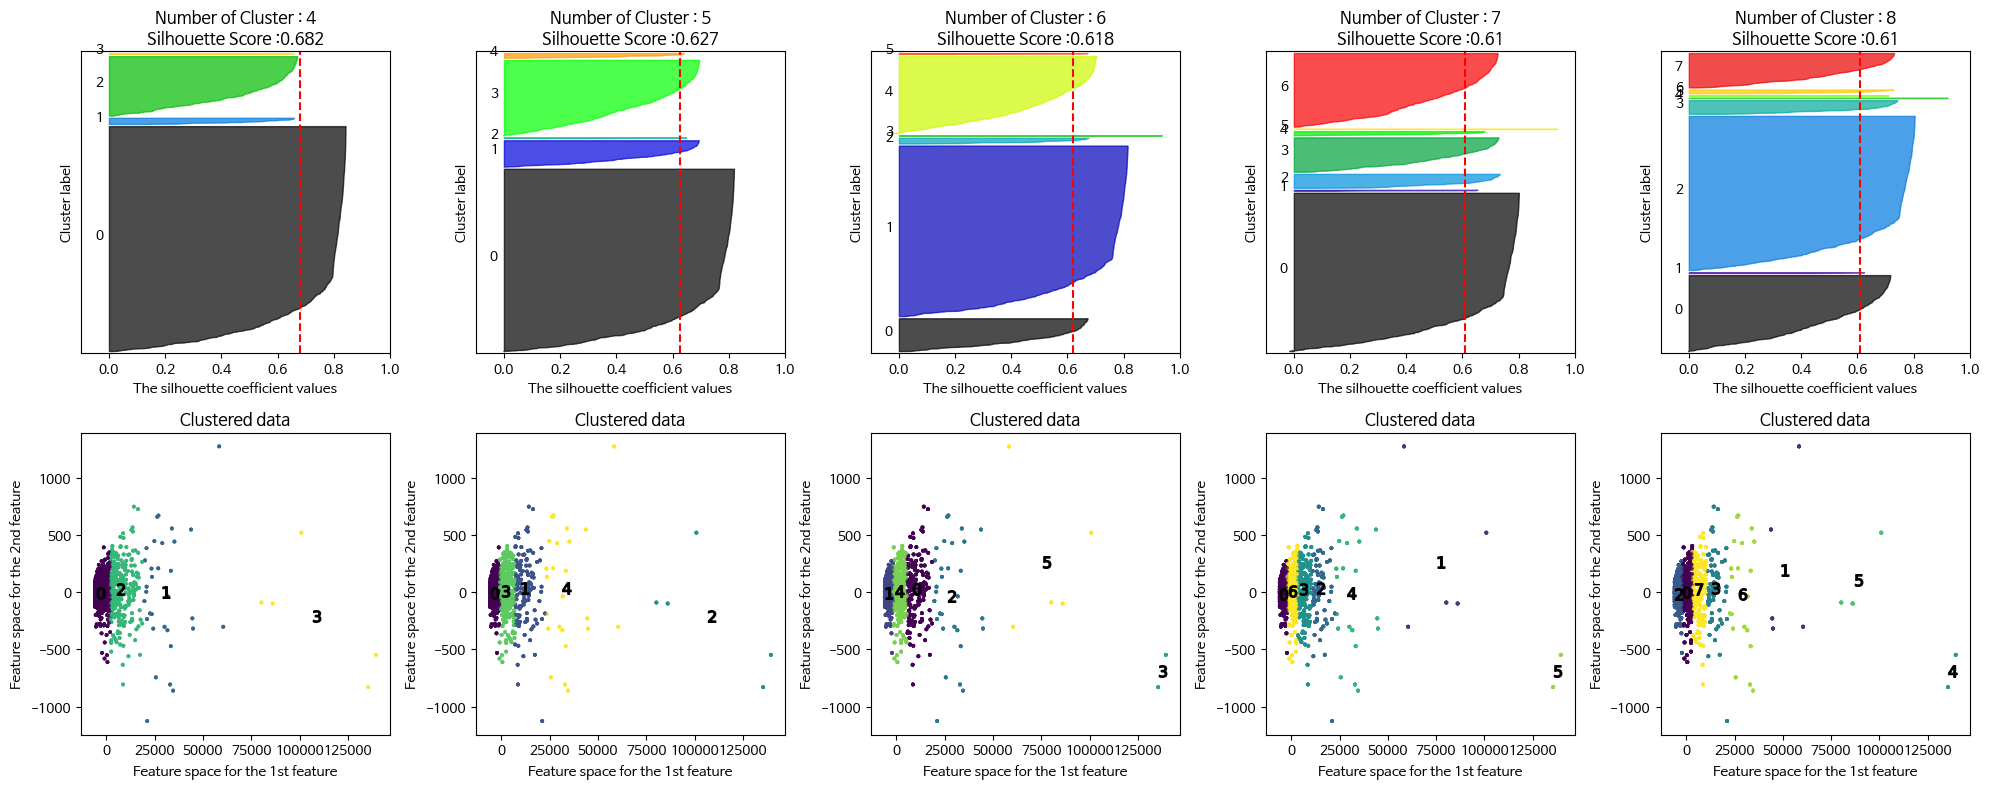

In [48]:
# cluster 개수를 2개, 3개, 4개, 5개, 6개, 7개 일때의 클러스터별 실루엣 계수 평균값을 시각화
visualize_silhouette_2d([4, 5, 6, 7, 8], pca_df)

- rs, ss, mm 스케일러 적용한 값 보다 스케일러 미적용이 클러스터링에 더 효과적이었음

---
# 이상치 제거 + 8개 Features PCA + Kmeans -> df
- 2차원으로 축소

In [49]:
pca = PCA(n_components=2)
principalComponents = pca.fit_transform(new_features_drop_iqr)
pca_drop_iqr_df = pd.DataFrame(data=principalComponents, columns=['1st', '2nd'])
pca_drop_iqr_df

,1st,2nd
0,-4098.753126,-71.789430
1,-1465.593562,-18.890055
2,-1725.147536,-229.706428
3,-1595.147787,-95.103135
4,-2985.350443,-43.534068
...,...,...
1363,-3120.232620,141.643122
1364,222.020043,-21.214305
1365,-3983.682743,62.967017
1366,-3622.951768,-145.096681


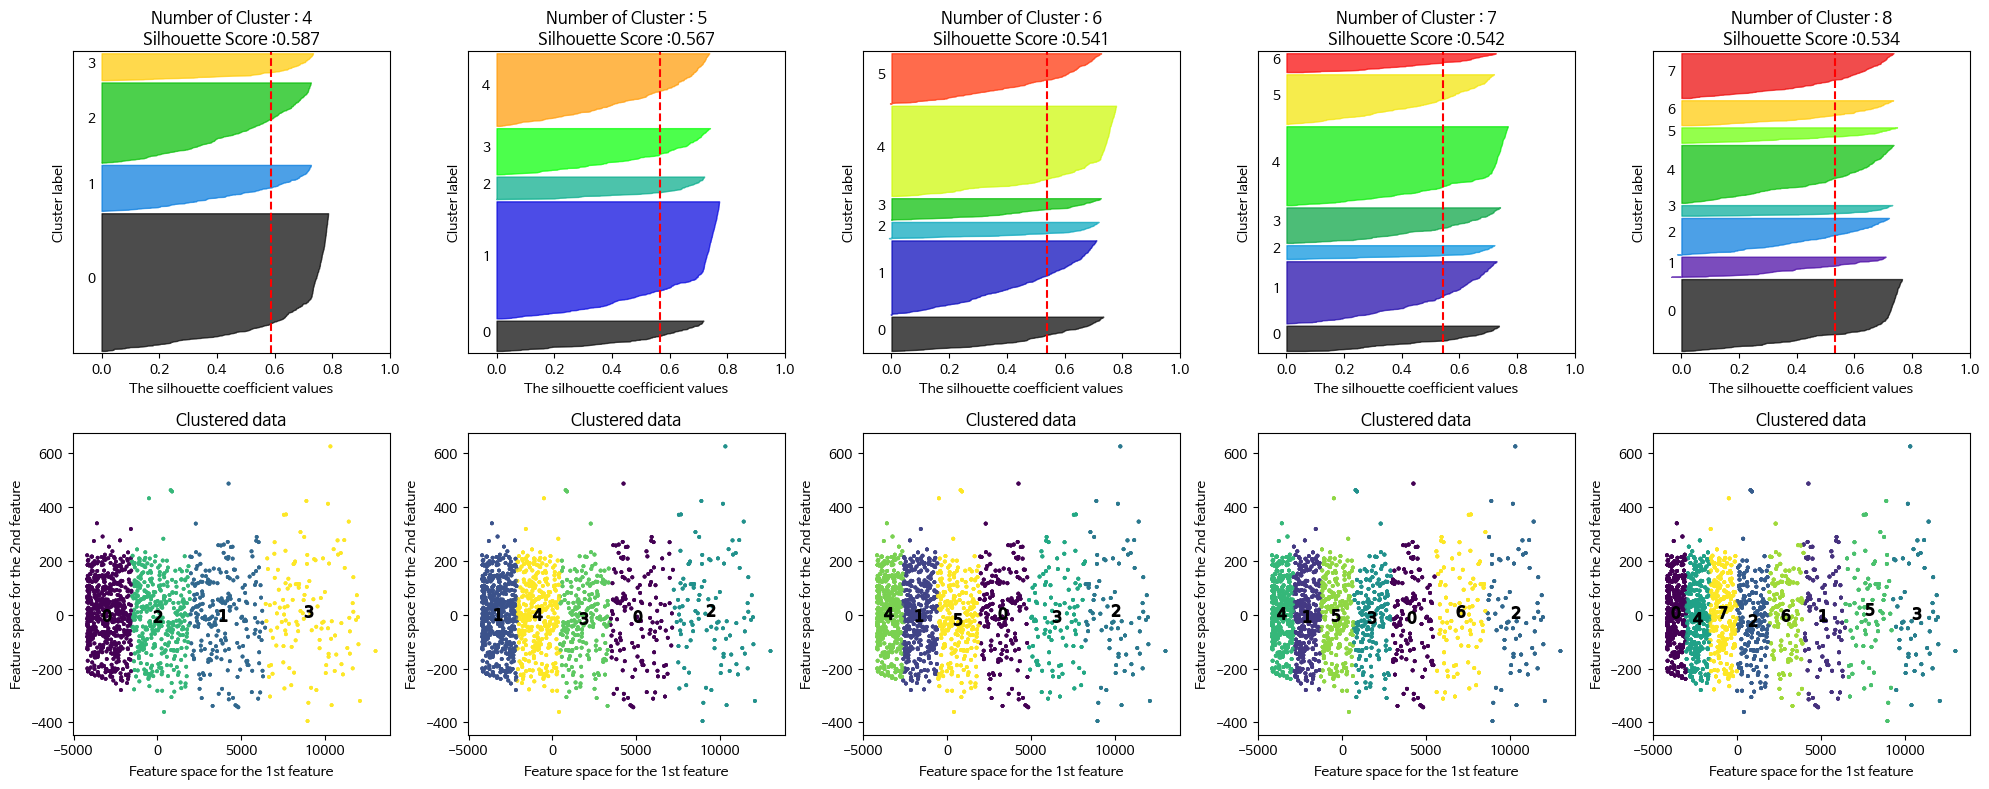

In [50]:
pca_drop_iqr_df_labels = visualize_silhouette_2d([4, 5, 6, 7, 8], pca_drop_iqr_df)

In [51]:
pca_drop_iqr_cluster = new_features_drop_iqr.copy()
pca_drop_iqr_cluster['Cluster'] = pca_drop_iqr_df_labels[4]
pca_drop_iqr_cluster

,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,Cluster
0,108,108,1,3,35.69,24.98,75.00,99.98,0
2,193,74,8,209,1645.73,1492.42,81.07,1573.49,2
3,18,18,11,21,1508.36,1339.57,82.39,1421.96,0
4,108,108,13,56,1594.23,1369.93,154.49,1524.42,0
5,131,131,3,86,696.47,688.02,18.00,706.02,0
...,...,...,...,...,...,...,...,...,...
1463,271,271,3,46,595.58,582.38,94.35,676.73,0
1464,193,88,19,141,2640.23,2384.13,222.05,2606.18,2
1465,271,195,2,10,119.58,115.40,12.50,127.90,0
1466,70,70,1,2,327.80,327.80,6.00,333.80,0


## Cluster 0 한 번 더 쪼개기
- 현재 이상치 1개 + 4개 Clustered Group

In [52]:
pca_drop_iqr_cluster_0 = pca_drop_iqr_cluster[pca_drop_iqr_cluster['Cluster'] == 0]
pca_drop_iqr_cluster_0

,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,Cluster
0,108,108,1,3,35.69,24.98,75.00,99.98,0
3,18,18,11,21,1508.36,1339.57,82.39,1421.96,0
4,108,108,13,56,1594.23,1369.93,154.49,1524.42,0
5,131,131,3,86,696.47,688.02,18.00,706.02,0
7,25,25,5,22,526.96,492.60,38.48,531.08,0
...,...,...,...,...,...,...,...,...,...
1458,109,109,1,50,109.45,76.61,6.00,82.61,0
1462,180,180,2,4,58.35,58.35,12.50,70.85,0
1463,271,271,3,46,595.58,582.38,94.35,676.73,0
1465,271,195,2,10,119.58,115.40,12.50,127.90,0


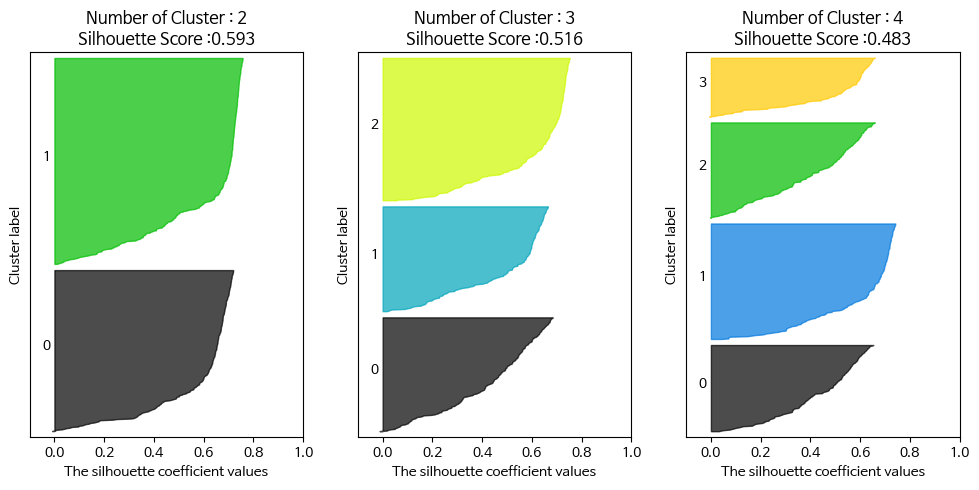

In [53]:
pca_drop_iqr_cluster_0_labels = visualize_silhouette([2, 3, 4], pca_drop_iqr_cluster_0)

In [54]:
pca_drop_iqr_cluster_0['Cluster'] = pca_drop_iqr_cluster_0_labels[2]
pca_drop_iqr_cluster_0['Cluster'].replace({0:4, 1:5}, inplace=True)
pca_drop_iqr_cluster_0

<ipython-input-54-fc99e8bf5b87>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pca_drop_iqr_cluster_0['Cluster'] = pca_drop_iqr_cluster_0_labels[2]
<ipython-input-54-fc99e8bf5b87>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pca_drop_iqr_cluster_0['Cluster'].replace({0:4, 1:5}, inplace=True)


,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,Cluster
0,108,108,1,3,35.69,24.98,75.00,99.98,5
3,18,18,11,21,1508.36,1339.57,82.39,1421.96,4
4,108,108,13,56,1594.23,1369.93,154.49,1524.42,4
5,131,131,3,86,696.47,688.02,18.00,706.02,4
7,25,25,5,22,526.96,492.60,38.48,531.08,5
...,...,...,...,...,...,...,...,...,...
1458,109,109,1,50,109.45,76.61,6.00,82.61,5
1462,180,180,2,4,58.35,58.35,12.50,70.85,5
1463,271,271,3,46,595.58,582.38,94.35,676.73,5
1465,271,195,2,10,119.58,115.40,12.50,127.90,5


In [55]:
for idx in pca_drop_iqr_cluster_0.index:
  pca_drop_iqr_cluster.loc[idx, 'Cluster'] = pca_drop_iqr_cluster_0.loc[idx, 'Cluster']

pca_drop_iqr_cluster

,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,Cluster
0,108,108,1,3,35.69,24.98,75.00,99.98,5
2,193,74,8,209,1645.73,1492.42,81.07,1573.49,2
3,18,18,11,21,1508.36,1339.57,82.39,1421.96,4
4,108,108,13,56,1594.23,1369.93,154.49,1524.42,4
5,131,131,3,86,696.47,688.02,18.00,706.02,4
...,...,...,...,...,...,...,...,...,...
1463,271,271,3,46,595.58,582.38,94.35,676.73,5
1464,193,88,19,141,2640.23,2384.13,222.05,2606.18,2
1465,271,195,2,10,119.58,115.40,12.50,127.90,5
1466,70,70,1,2,327.80,327.80,6.00,333.80,5


## 이상치 그룹을 6으로 추가하기
- 이상치 1개 + clustered group 6개


In [56]:
pca_iqr_df = pd.concat([pca_drop_iqr_cluster, new_features_df_high], axis=0).sort_index()
pca_iqr_df

,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,Cluster
0,108,108,1,3,35.69,24.98,75.00,99.98,5
1,283,60,31,342,15902.78,15021.67,286.46,15308.13,6
2,193,74,8,209,1645.73,1492.42,81.07,1573.49,2
3,18,18,11,21,1508.36,1339.57,82.39,1421.96,4
4,108,108,13,56,1594.23,1369.93,154.49,1524.42,4
...,...,...,...,...,...,...,...,...,...
1463,271,271,3,46,595.58,582.38,94.35,676.73,5
1464,193,88,19,141,2640.23,2384.13,222.05,2606.18,2
1465,271,195,2,10,119.58,115.40,12.50,127.90,5
1466,70,70,1,2,327.80,327.80,6.00,333.80,5


In [57]:
pca_iqr_df = pd.concat([customer_buyinginfo_df, pca_iqr_df['Cluster']], axis=1)
pca_iqr_df

,고객ID,가입날짜,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,평균결제금액,평균할인차액,평균할인비율,구매제품평균금액,Cluster
0,USER_0000,988,108,108,1,3,35.69,24.98,75.00,99.98,99.98,-10.71,0.11,8.33,5
1,USER_0001,659,283,60,31,342,15902.78,15021.67,286.46,15308.13,493.81,-28.42,0.06,43.92,6
2,USER_0002,1205,193,74,8,209,1645.73,1492.42,81.07,1573.49,196.69,-19.16,0.10,7.14,2
3,USER_0003,764,18,18,11,21,1508.36,1339.57,82.39,1421.96,129.27,-15.34,0.12,63.79,4
4,USER_0004,988,108,108,13,56,1594.23,1369.93,154.49,1524.42,117.26,-17.25,0.15,24.46,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1463,USER_1463,183,271,271,3,46,595.58,582.38,94.35,676.73,225.58,-4.40,0.02,12.66,5
1464,USER_1464,1352,193,88,19,141,2640.23,2384.13,222.05,2606.18,137.17,-13.48,0.10,16.91,2
1465,USER_1465,764,271,195,2,10,119.58,115.40,12.50,127.90,63.95,-2.09,0.03,11.54,5
1466,USER_1466,1499,70,70,1,2,327.80,327.80,6.00,333.80,333.80,0.00,0.00,163.90,5


---
# RMF Cluster

In [58]:
# 2019년 말일 기준으로 최근 거래일을 일로 환산하기
today = datetime.date(2019, 12, 31)

rfm_df = customer_buyinginfo_df[['최근거래날짜', '구매횟수', '총결제금액']].copy()
rfm_df.columns = ['R', 'F', 'M']
rfm_df


,R,F,M
0,108,1,99.98
1,60,31,15308.13
2,74,8,1573.49
3,18,11,1421.96
4,108,13,1524.42
...,...,...,...
1463,271,3,676.73
1464,88,19,2606.18
1465,195,2,127.90
1466,70,1,333.80


In [59]:
kmeans = KMeans(n_clusters=5)
kmeans.fit(rfm_df)
rfm_df['Cluster'] = kmeans.predict(rfm_df)
rfm_df

,R,F,M,Cluster
0,108,1,99.98,3
1,60,31,15308.13,2
2,74,8,1573.49,3
3,18,11,1421.96,3
4,108,13,1524.42,3
...,...,...,...,...
1463,271,3,676.73,3
1464,88,19,2606.18,3
1465,195,2,127.90,3
1466,70,1,333.80,3


In [60]:
rfm_df.groupby('Cluster').describe().T

Cluster            0             1             2            3             4
R count   383.000000      5.000000    149.000000   905.000000     26.000000
  mean    126.334204     30.200000     97.469799   163.602210     83.423077
  std      98.922086     43.928351     93.076586   100.082327     92.384489
  min       1.000000      1.000000      4.000000     1.000000      2.000000
  25%      41.500000     11.000000     32.000000    81.000000     23.250000
  50%     102.000000     13.000000     61.000000   153.000000     48.500000
  75%     193.000000     18.000000    138.000000   240.000000    110.000000
  max     362.000000    108.000000    363.000000   365.000000    340.000000
F count   383.000000      5.000000    149.000000   905.000000     26.000000
  mean     24.342037    289.400000     48.536913     6.861878     93.038462
  std       8.369446     24.337214     16.470089     4.740120     42.085133
  min       2.000000    263.000000      4.000000     1.000000     24.000000
  25%      18.000000    276.000000     38.000000     3.000000     60.500000
  50%      24.000000    289.000000     46.000000     6.000000     91.500000
  75%      30.000000    291.000000     59.000000    10.000000    119.250000
  max      53.000000    328.000000     99.000000    23.000000    177.000000
M count   383.000000      5.000000    149.000000   905.000000     26.000000
  mean   4470.735822  66491.270000   9960.150067  1072.433923  22321.573462
  std    1227.012337  16007.183636   2170.041371   784.502072   5952.065321
  min    2767.720000  50110.170000   7239.190000     6.990000  16332.710000
  25%    3403.620000  53883.430000   8138.410000   374.280000  17960.645000
  50%    4239.610000  61651.340000   9305.990000   967.740000  21576.545000
  75%    5403.705000  82405.580000  11482.700000  1691.380000  22982.292500
  max    7127.250000  84405.830000  15984.290000  2762.740000  39126.840000

In [61]:
tmp_df = rfm_df.groupby('Cluster').mean()
tmp_df

,R,F,M
Cluster,,,
0,126.334204,24.342037,4470.735822
1,30.200000,289.400000,66491.270000
2,97.469799,48.536913,9960.150067
3,163.602210,6.861878,1072.433923
4,83.423077,93.038462,22321.573462


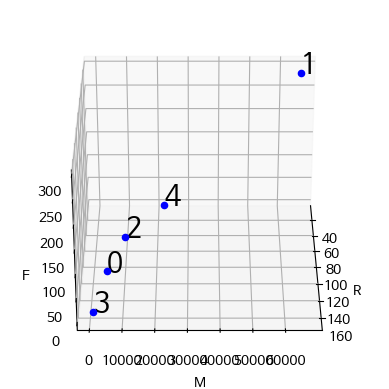

In [62]:
from mpl_toolkits.mplot3d import axes3d
from IPython.display import HTML
from matplotlib import animation

tmp_df = rfm_df.groupby('Cluster').mean()

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for i in range(len(tmp_df)): # plot each point + it's index as text above
  x = tmp_df['R'][i]
  y = tmp_df['M'][i]
  z = tmp_df['F'][i]
  label = i
  ax.scatter(x, y, z, color='b')
  ax.text(x, y, z, '%s' % (label), size=20, zorder=1, color='k')

ax.set_xlabel('R')
ax.set_ylabel('M')
ax.set_zlabel('F')

def animate(frame):
  ax.view_init(30, frame/4)
  plt.pause(.001)
  return fig

anim = animation.FuncAnimation(fig, animate, frames=200, interval=50)
HTML(anim.to_html5_video())

{4: array([0, 1, 0, ..., 0, 0, 3], dtype=int32),
 5: array([0, 3, 0, ..., 0, 0, 4], dtype=int32),
 6: array([1, 2, 1, ..., 1, 1, 0], dtype=int32),
 7: array([6, 3, 6, ..., 6, 6, 0], dtype=int32),
 8: array([3, 7, 3, ..., 3, 3, 5], dtype=int32)}

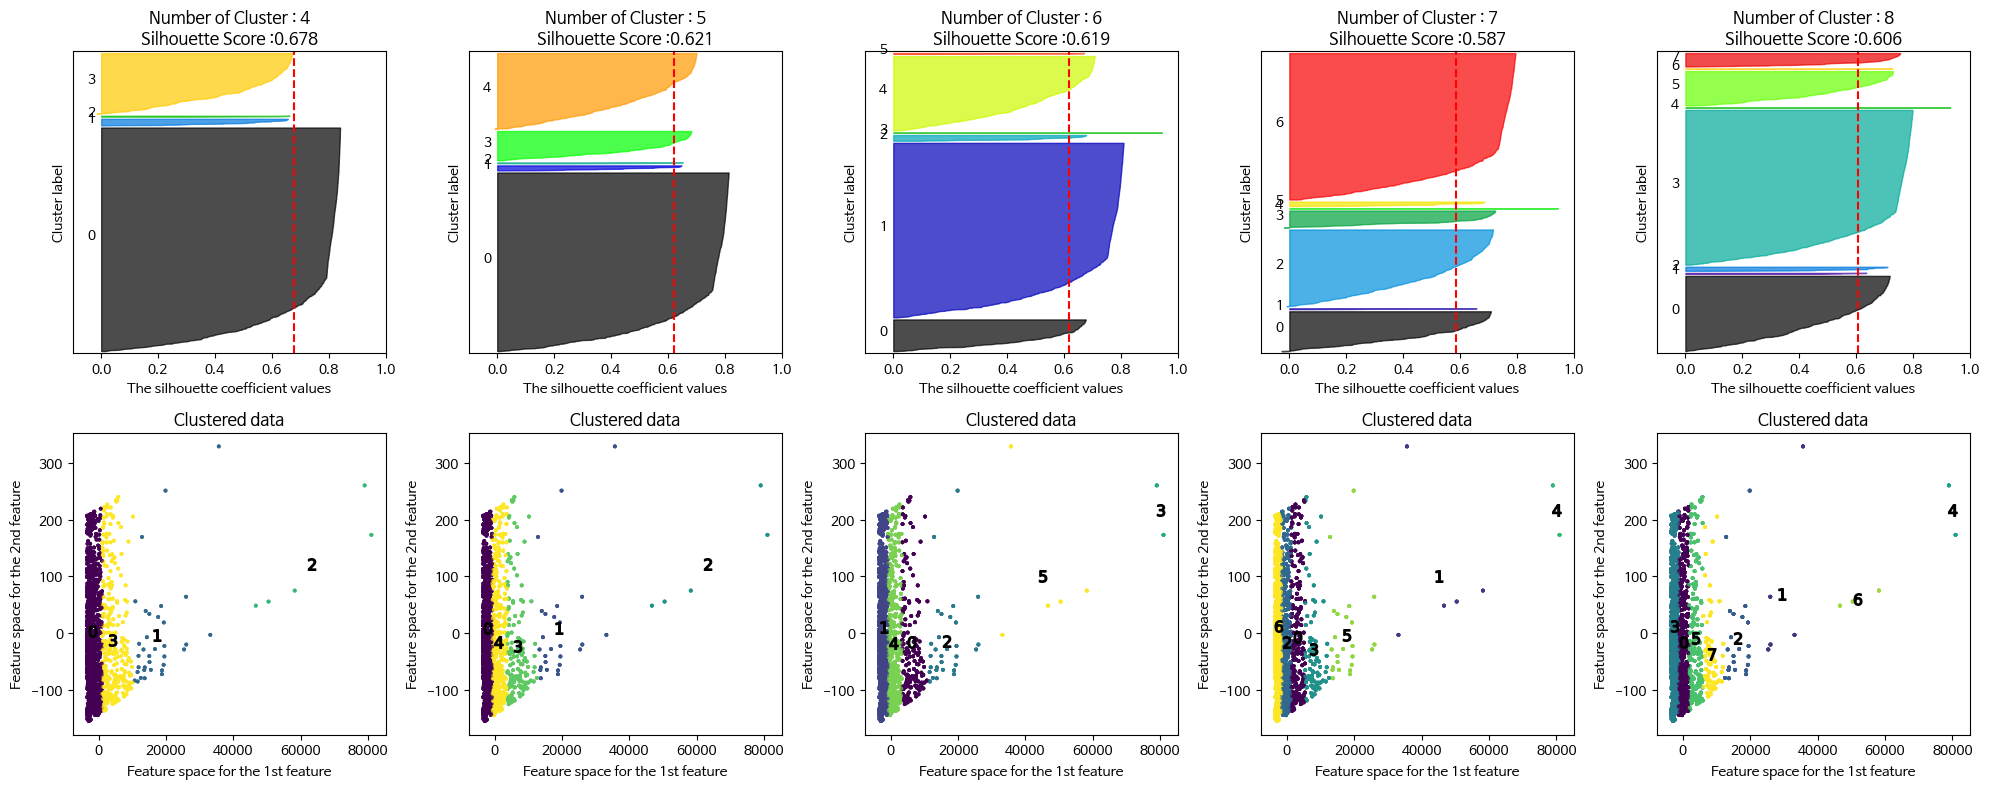

In [63]:
# cluster 개수를 2개, 3개, 4개, 5개, 6개, 7개 일때의 클러스터별 실루엣 계수 평균값을 시각화
from sklearn.decomposition import PCA

# PCA 변환
pca = PCA(n_components=2)
principalComponents = pca.fit_transform(rfm_df.drop('Cluster', axis=1))
rfm_pca_df = pd.DataFrame(data=principalComponents, columns=['1st', '2nd'])
rfm_pca_df

visualize_silhouette_2d([4, 5, 6, 7, 8], rfm_pca_df)

---

# 8 features PCA + SS + DBSCAN -> df

- K-means 알고리즘은 평균을 취하기 때문에 이상치에 민감하며, DBSCAN은 잡음점을 식별하므로 이상치에 민감하지 않다(robust).

- 클러스터링 과정 구현<br>
DBSCAN은 feature 간 거리를 기준으로 클러스터를 구성하는 알고리즘으로,이 과정을 위해서는 정규화가 필수적입니다.
DBSCAN 군집화를 위해서는 현재 군집 상태로부터 최대 탐색 거리를 의미하는 epsilon 값(반지름)과 클러스터로 구성되기 위한 최소 샘플 개수인 min_samples 값을 지정해주어야 합니다.

In [64]:
pca_df.head(2)

,1st,2nd
0,-5852.953742,9.100289
1,20749.573291,385.916257


In [65]:
ss_pca_df = pd.DataFrame(ss.fit_transform(pca_df))
ss_pca_df.head(2)

,0,1
0,-0.615507,0.057450
1,2.182062,2.436296


In [66]:
from sklearn.cluster import DBSCAN

# create model and prediction
dbscan = DBSCAN(eps=0.6, min_samples=10)
cluster = pd.DataFrame(dbscan.fit_predict(ss_pca_df))
cluster.columns=['Cluster']

# concatenate labels to df as a new column
dbscan_df = pd.concat([ss_pca_df, cluster], axis=1)
dbscan_df.head(2)


,0,1,Cluster
0,-0.615507,0.057450,0
1,2.182062,2.436296,0


In [67]:
dbscan_df.value_counts('Cluster')

Cluster
 0    1421
-1      47
dtype: int64

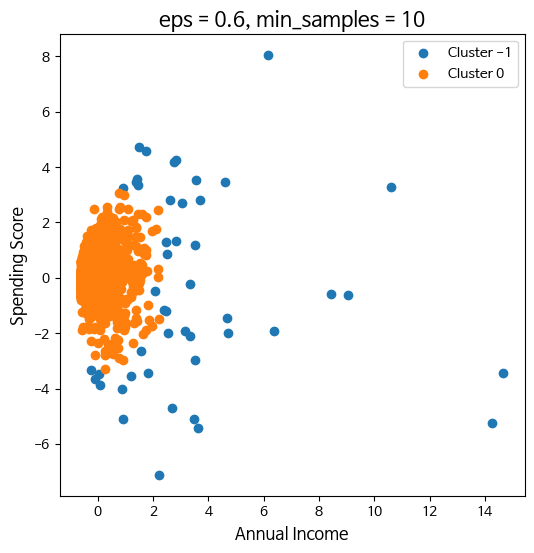

In [68]:
plt.figure(figsize = (6, 6))

# 이상치 번호는 -1, 클러스터 최대 숫자까지 iteration
for i in range(-1, dbscan_df['Cluster'].max() + 1):
    plt.scatter(dbscan_df.loc[dbscan_df['Cluster'] == i, 0], dbscan_df.loc[dbscan_df['Cluster'] == i, 1], label = 'Cluster ' + str(i))

plt.legend()
plt.title('eps = 0.6, min_samples = 10', size = 15)
plt.xlabel('Annual Income', size = 12)
plt.ylabel('Spending Score', size = 12)
plt.show()

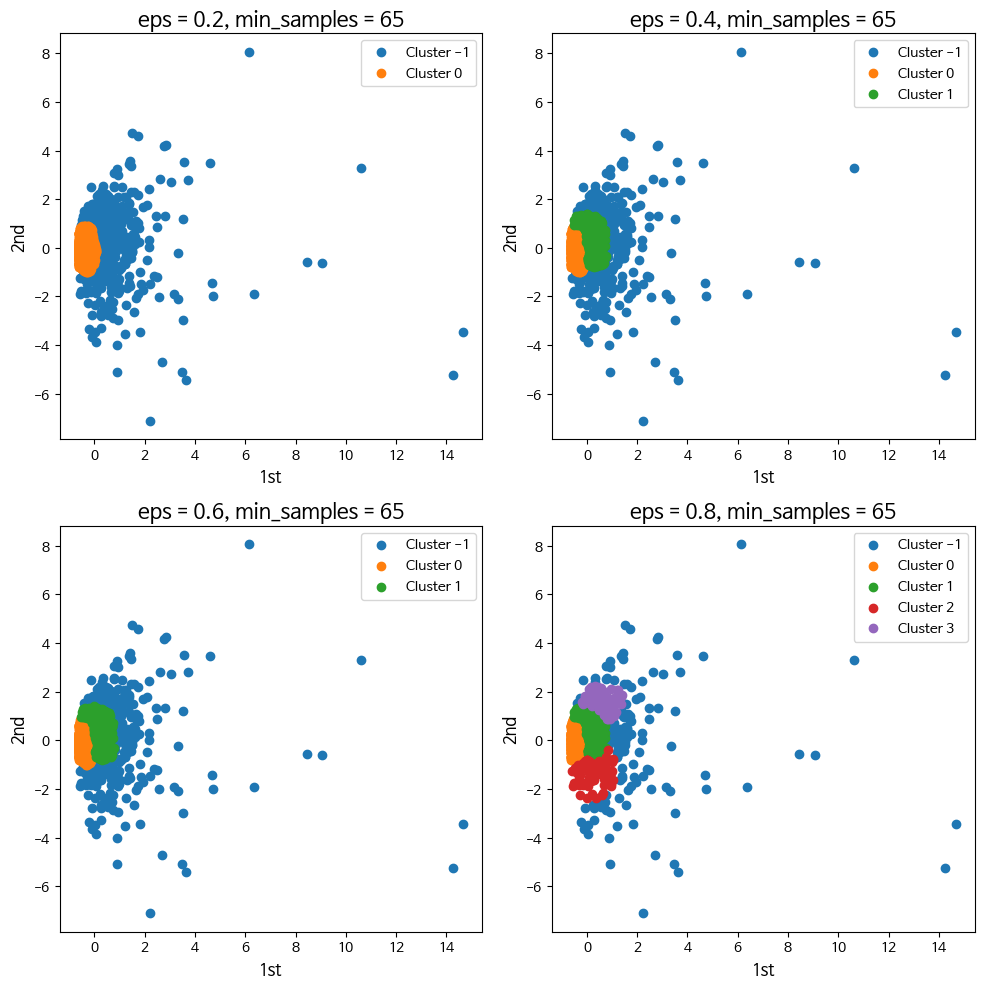

In [69]:
def draw_dbscan(scaled_df):
  # 다중 플롯 동시 시각화

  f, ax = plt.subplots(2, 2, figsize=(10, 10))

  for i in range(4):
    # epsilon을 증가시키면서 반복
    eps = 0.2 * (i + 1)
    min_samples = 65

    # 군집화 및 시각화 과정 자동화
    model = DBSCAN(eps=eps, min_samples=min_samples)

    model.fit(scaled_df)
    scaled_df['Cluster'] = model.fit_predict(scaled_df)
    scaled_df.columns = ['1st', '2nd', 'Cluster']

    for j in range(-1, scaled_df['Cluster'].max() + 1):
        ax[i // 2, i % 2].scatter(scaled_df.loc[scaled_df['Cluster'] == j, '1st'], scaled_df.loc[scaled_df['Cluster'] == j, '2nd'],
                        label = 'Cluster ' + str(j))

    ax[i // 2, i % 2].legend()
    ax[i // 2, i % 2].set_title('eps = %.1f, min_samples = %d'%(eps, min_samples), size = 15)
    ax[i // 2, i % 2].set_xlabel(scaled_df.columns[0], size = 12)
    ax[i // 2, i % 2].set_ylabel(scaled_df.columns[1], size = 12)
  plt.tight_layout()
  plt.show()

  return scaled_df

tmp_df = draw_dbscan(ss_pca_df)

---

In [70]:
dbscan_df = pd.concat([customer_buyinginfo_df, tmp_df['Cluster']], axis=1)
dbscan_df

,고객ID,가입날짜,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,평균결제금액,평균할인차액,평균할인비율,구매제품평균금액,Cluster
0,USER_0000,988,108,108,1,3,35.69,24.98,75.00,99.98,99.98,-10.71,0.11,8.33,0
1,USER_0001,659,283,60,31,342,15902.78,15021.67,286.46,15308.13,493.81,-28.42,0.06,43.92,-1
2,USER_0002,1205,193,74,8,209,1645.73,1492.42,81.07,1573.49,196.69,-19.16,0.10,7.14,0
3,USER_0003,764,18,18,11,21,1508.36,1339.57,82.39,1421.96,129.27,-15.34,0.12,63.79,1
4,USER_0004,988,108,108,13,56,1594.23,1369.93,154.49,1524.42,117.26,-17.25,0.15,24.46,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1463,USER_1463,183,271,271,3,46,595.58,582.38,94.35,676.73,225.58,-4.40,0.02,12.66,0
1464,USER_1464,1352,193,88,19,141,2640.23,2384.13,222.05,2606.18,137.17,-13.48,0.10,16.91,0
1465,USER_1465,764,271,195,2,10,119.58,115.40,12.50,127.90,63.95,-2.09,0.03,11.54,0
1466,USER_1466,1499,70,70,1,2,327.80,327.80,6.00,333.80,333.80,0.00,0.00,163.90,0


---
# DF 정리
- 8 Features + IQR + 6개로 그룹화한 df: iqr_df
- 8 Features + IQR + pca + 6개로 그룹화한 df: pca_iqr_df
- 8 Features + pca + dbscan(0.8, 60) + 6개로 그룹화(이상치그룹 포함): dbscan_df

In [71]:
iqr_df.value_counts('Cluster', sort=False)

Cluster
1    217
2    377
3    127
4    284
5    363
6    100
dtype: int64

In [72]:
pca_iqr_df.value_counts('Cluster', sort=False)

Cluster
1    217
2    377
3    127
4    284
5    363
6    100
dtype: int64

- Kmeans의 경우 PCA를 한 것과 하지 않은 경우가 동일하기 때문에 한 것으로 진행

- dbscan에서 이상치그룹 4로 변경

In [73]:
dbscan_df['Cluster'].replace({-1:4}, inplace=True)

In [74]:
dbscan_df.value_counts('Cluster', sort=False)

Cluster
0    920
1    247
2     93
3     68
4    140
dtype: int64

- 더 세밀하게 분배된 것으로 보이는 pca_iqr_df로 사용

---
# EDA

In [95]:
df = pca_iqr_df.copy()
df

,고객ID,가입날짜,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,평균결제금액,평균할인차액,평균할인비율,구매제품평균금액,Cluster
0,USER_0000,988,108,108,1,3,35.69,24.98,75.00,99.98,99.98,-10.71,0.11,8.33,5
1,USER_0001,659,283,60,31,342,15902.78,15021.67,286.46,15308.13,493.81,-28.42,0.06,43.92,6
2,USER_0002,1205,193,74,8,209,1645.73,1492.42,81.07,1573.49,196.69,-19.16,0.10,7.14,2
3,USER_0003,764,18,18,11,21,1508.36,1339.57,82.39,1421.96,129.27,-15.34,0.12,63.79,4
4,USER_0004,988,108,108,13,56,1594.23,1369.93,154.49,1524.42,117.26,-17.25,0.15,24.46,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1463,USER_1463,183,271,271,3,46,595.58,582.38,94.35,676.73,225.58,-4.40,0.02,12.66,5
1464,USER_1464,1352,193,88,19,141,2640.23,2384.13,222.05,2606.18,137.17,-13.48,0.10,16.91,2
1465,USER_1465,764,271,195,2,10,119.58,115.40,12.50,127.90,63.95,-2.09,0.03,11.54,5
1466,USER_1466,1499,70,70,1,2,327.80,327.80,6.00,333.80,333.80,0.00,0.00,163.90,5


In [96]:
df.groupby('Cluster').mean()

,가입날짜,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,평균결제금액,평균할인차액,평균할인비율,구매제품평균금액
Cluster,,,,,,,,,,,,,
1,805.290323,220.142857,128.248848,25.705069,209.580645,4804.550184,4474.584378,227.757788,4702.342166,195.367972,-13.402304,0.070323,37.533364
2,827.779841,206.116711,140.994695,13.941645,116.408488,2495.217321,2321.475119,122.882918,2444.358037,199.400106,-13.892149,0.071645,39.396684
3,839.842520,244.543307,124.881890,37.858268,340.559055,7845.280709,7329.862283,342.200709,7672.062992,235.161811,-15.057874,0.067638,34.229843
4,847.605634,189.007042,156.746479,7.091549,48.957746,1123.524789,1046.705986,64.757077,1111.463063,187.710246,-12.080246,0.069331,45.827711
5,800.118457,197.804408,177.258953,3.005510,18.920110,299.973196,277.186336,26.764105,303.950441,110.399146,-7.574683,0.071791,33.152507
6,828.680000,257.530000,75.830000,78.840000,846.450000,17777.407500,16657.799600,716.714300,17374.513900,245.640200,-15.501400,0.065900,26.077200


In [97]:
df.groupby('Cluster').mean().describe()

,가입날짜,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,평균결제금액,평균할인차액,평균할인비율,구매제품평균금액
count,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000
mean,824.886129,219.190721,133.993477,27.740340,263.479341,5724.325616,5351.268950,250.179483,5601.448433,195.613247,-12.918109,0.069438,36.036218
std,18.762035,27.029314,34.460497,28.093695,308.596730,6505.986905,6098.791193,255.783381,6354.393450,47.759995,2.887539,0.002322,6.635787
min,800.118457,189.007042,75.830000,3.005510,18.920110,299.973196,277.186336,26.764105,303.950441,110.399146,-15.501400,0.065900,26.077200
25%,810.912702,199.882484,125.723629,8.804073,65.820432,1466.447922,1365.398269,79.288538,1444.686807,189.624678,-14.766443,0.068061,33.421841
50%,828.229920,213.129784,134.621771,19.823357,162.994567,3649.883753,3398.029749,175.320353,3573.350102,197.384039,-13.647226,0.069827,35.881603
75%,837.051890,238.443195,152.808533,34.819968,307.814453,7085.098078,6616.042807,313.589979,6929.632786,226.221385,-12.410761,0.071314,38.930854
max,847.605634,257.530000,177.258953,78.840000,846.450000,17777.407500,16657.799600,716.714300,17374.513900,245.640200,-7.574683,0.071791,45.827711


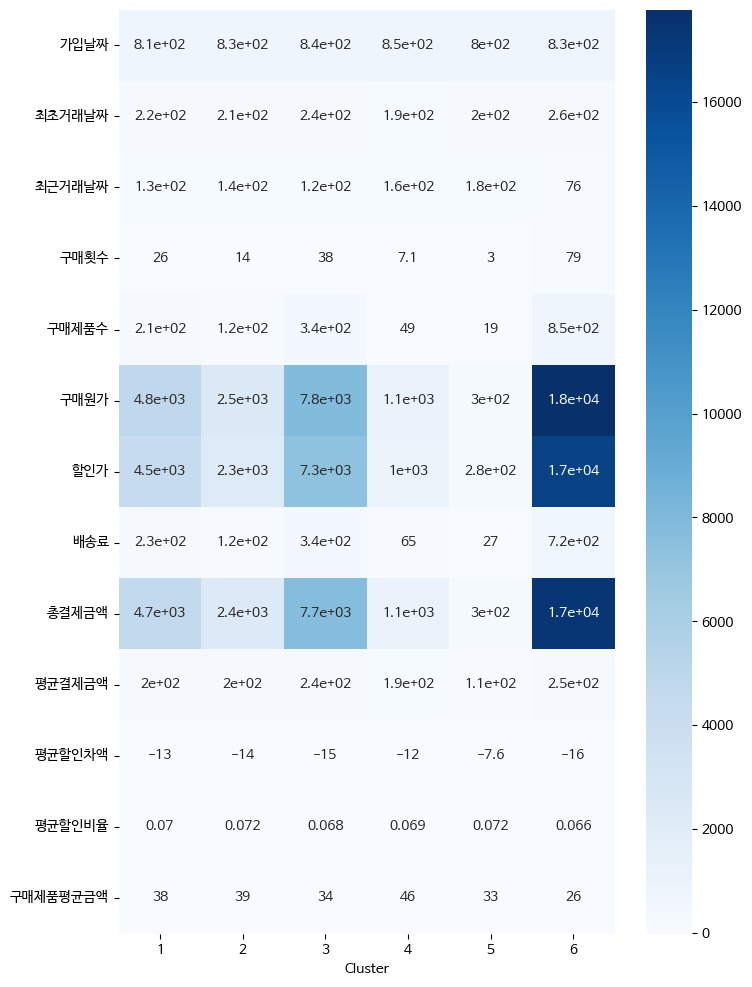

In [98]:
plt.figure(figsize=(8, 12))
sns.heatmap(df.groupby('Cluster').mean().T, annot=True, cmap='Blues')
plt.show()

## 고객구분
- 구매제품평균금액(할인가/구매제품수)은 고객 등급을 정하는 데에는 크게 반영하지 않음.
- 저렴한 제품을 대량 구매하는 경우, 총결제금액은 높지만 구매제품평균금액은 낮아지기 때문.
- 단, 마케팅 전략에서도 총결제금액 기준으로 할인 정책을 세워야 함.

<center>
<img src='https://drive.google.com/uc?id=1G43eaELWlMAJ7-9oGpRIYhuAETT4dyIJ' width='1300' height ='250' /><br>
</center>

- 고객 그룹 6단계
  - VVIP: 6
  - VIP: 3
  - Newcomer: 1
  - Need Attention: 2
  - About to Sleep: 4
  - Sleep: 5

In [99]:
groupname = {1: 'Newcomer', 2: 'Need Attention', 3: 'VIP', 4: 'About to Sleep', 5: 'Sleep', 6: 'VVIP'}
df['Cluster'].replace(groupname, inplace=True)
df

,고객ID,가입날짜,최초거래날짜,최근거래날짜,구매횟수,구매제품수,구매원가,할인가,배송료,총결제금액,평균결제금액,평균할인차액,평균할인비율,구매제품평균금액,Cluster
0,USER_0000,988,108,108,1,3,35.69,24.98,75.00,99.98,99.98,-10.71,0.11,8.33,Sleep
1,USER_0001,659,283,60,31,342,15902.78,15021.67,286.46,15308.13,493.81,-28.42,0.06,43.92,VVIP
2,USER_0002,1205,193,74,8,209,1645.73,1492.42,81.07,1573.49,196.69,-19.16,0.10,7.14,Need Attention
3,USER_0003,764,18,18,11,21,1508.36,1339.57,82.39,1421.96,129.27,-15.34,0.12,63.79,About to Sleep
4,USER_0004,988,108,108,13,56,1594.23,1369.93,154.49,1524.42,117.26,-17.25,0.15,24.46,About to Sleep
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1463,USER_1463,183,271,271,3,46,595.58,582.38,94.35,676.73,225.58,-4.40,0.02,12.66,Sleep
1464,USER_1464,1352,193,88,19,141,2640.23,2384.13,222.05,2606.18,137.17,-13.48,0.10,16.91,Need Attention
1465,USER_1465,764,271,195,2,10,119.58,115.40,12.50,127.90,63.95,-2.09,0.03,11.54,Sleep
1466,USER_1466,1499,70,70,1,2,327.80,327.80,6.00,333.80,333.80,0.00,0.00,163.90,Sleep


In [109]:
# 저장
# df.to_csv('customer_cluster_0_kimjihyun.csv', sep=',', encoding='utf8')

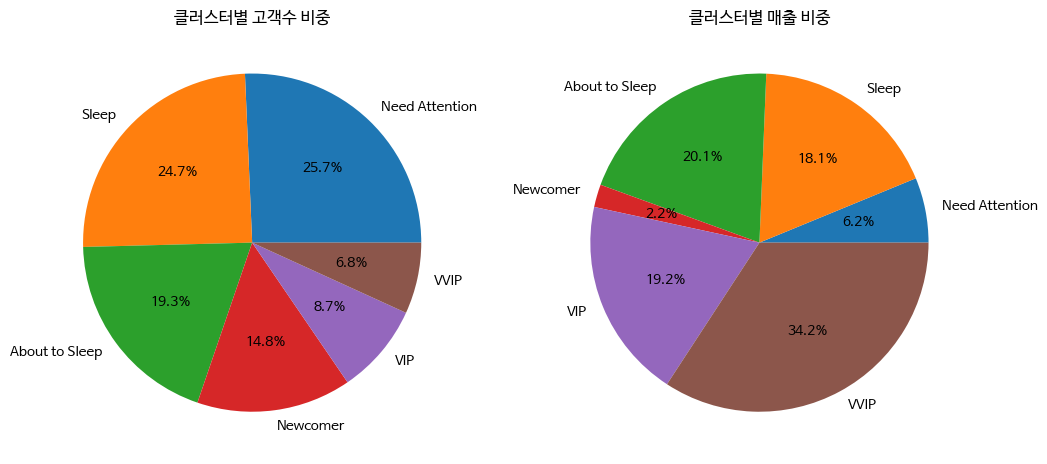

In [108]:
plt.figure(figsize=(12, 8))

plt.subplot(121)
plt.pie(df['Cluster'].value_counts(), autopct='%1.1f%%', labels=df['Cluster'].value_counts().index)
plt.title('클러스터별 고객수 비중')

plt.subplot(122)
plt.pie(df.groupby('Cluster')['총결제금액'].sum(), autopct='%1.1f%%', labels=df['Cluster'].value_counts().index)
plt.title('클러스터별 매출 비중')

plt.show()

- 우량고객과 신규고객(Newcomer, VIP, VVIP)에 비해 관심과 유도가 많이 필요한 Need Attention, About to Sleep, Sleep 고객들이 70%의 비중을 차지하는 것으로 나타났다.
- 매출 향상을 위해 고객 수 비중과 매출 비중에서 큰 비중을 차지하는 3가지 하위 그룹에 대한 적극적인 마케팅 전략을 펼쳐야 한다.

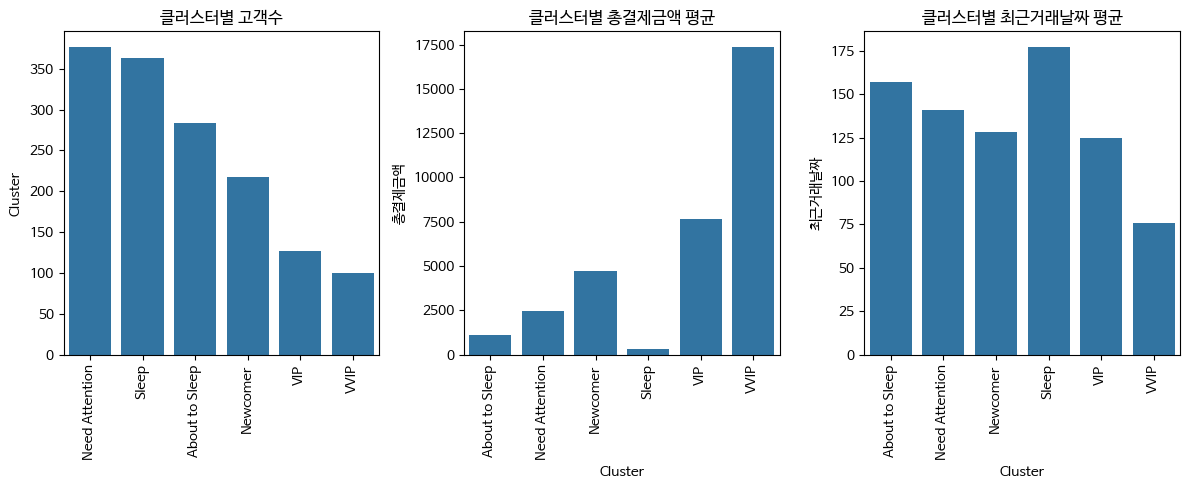

In [129]:
plt.figure(figsize=(12, 5))

plt.subplot(131)
sns.barplot(df['Cluster'].value_counts())
plt.xticks(rotation=90)
plt.title('클러스터별 고객수')

plt.subplot(132)
sns.barplot(df.groupby('Cluster')['총결제금액'].mean())
plt.xticks(rotation=90)
plt.title('클러스터별 총결제금액 평균')

plt.subplot(133)
sns.barplot(df.groupby('Cluster')['최근거래날짜'].mean())
plt.xticks(rotation=90)
plt.title('클러스터별 최근거래날짜 평균')   # 낮을 수록 좋음

plt.tight_layout()
plt.show()

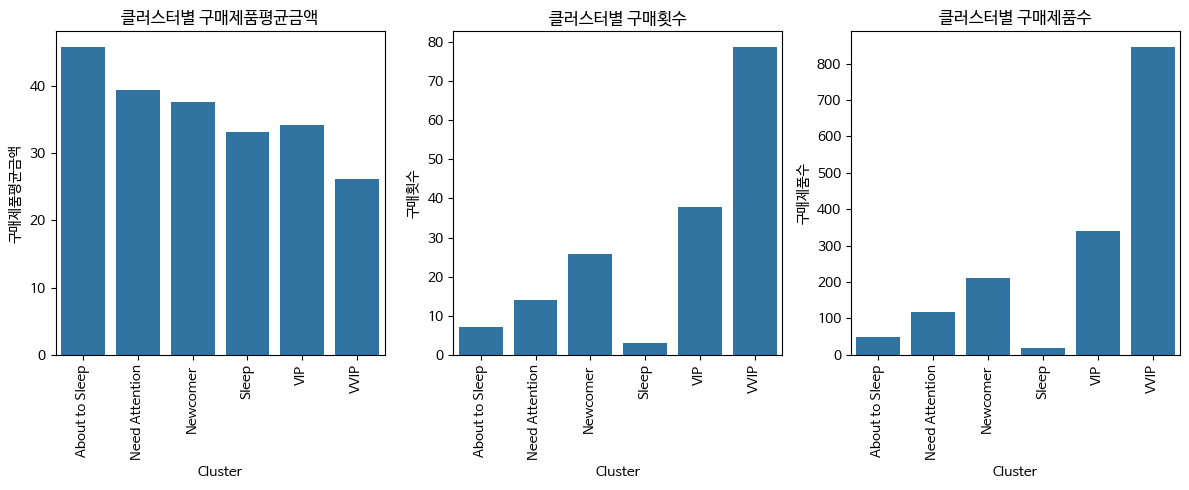

In [128]:
plt.figure(figsize=(12, 5))

plt.subplot(131)
sns.barplot(df.groupby('Cluster')['구매제품평균금액'].mean())
plt.xticks(rotation=90)
plt.title('클러스터별 구매제품평균금액')

plt.subplot(132)
sns.barplot(df.groupby('Cluster')['구매횟수'].mean())
plt.xticks(rotation=90)
plt.title('클러스터별 구매횟수')

plt.subplot(133)
sns.barplot(df.groupby('Cluster')['구매제품수'].mean())
plt.xticks(rotation=90)
plt.title('클러스터별 구매제품수')

plt.tight_layout()
plt.show()